# Generative Models: VAEs and a Latent Diffusion Model for Hot-Dog Images

In [ ]:
import importlib.util
import sys
# Dictionary mapping package names to their pip install names
packages = {
    'torch': 'torch torchvision altair seaborn',
    'accelerate': 'accelerate', 
    'huggingface_hub': '--upgrade huggingface_hub',
    'ipywidgets': 'ipywidgets',
    'sklearn': 'scikit-learn',
    'tqdm': 'tqdm',
    'transformers': 'transformers',
    'diffusers': 'diffusers[torch]',
    'einops': 'einops'
}

# Check which packages are missing
missing_packages = []
for package, pip_name in packages.items():
    if importlib.util.find_spec(package) is None:
        missing_packages.append(pip_name)

# Install all missing packages in a single pip call
if len(missing_packages) > 0:
    !{sys.executable} -m pip install {' '.join(missing_packages)}

import os
if not os.path.exists('icl_dl_cw2_utils'):
    !git clone -q https://github.com/bkainz/icl_dl_cw2_utils

In [ ]:
import tqdm
import os
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, sampler

from icl_dl_cw2_utils.utils.hotdogdataset import DLHotDogDataset
from torchvision import transforms, datasets
from torchvision.utils import save_image, make_grid

In [ ]:
# Check available CUDA devices and memory
if torch.cuda.is_available():
    num_devices = torch.cuda.device_count()
    for i in range(num_devices):
        device = torch.cuda.device(i)
        total_mem = torch.cuda.get_device_properties(i).total_memory / 1024**3  # Convert to GB
        allocated_mem = torch.cuda.memory_allocated(i) / 1024**3  # Convert to GB
        free_mem = total_mem - allocated_mem
        
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
        print(f"Total Memory: {total_mem:.1f}GB")
        print(f"Allocated Memory: {allocated_mem:.1f}GB")
        print(f"Free Memory: {free_mem:.1f}GB")
        
        if free_mem < 8:
            print(f"Warning: GPU {i} has less than 8GB of free VRAM!")
        else:
            print(f"Using GPU {i} with {free_mem:.1f}GB free VRAM")
            break 
    device = torch.device(f"cuda:{i}")
else:
    print("Warning: No CUDA devices available - running on CPU only")
    device = torch.device("cpu")

GPU 0: Tesla T4
Total Memory: 15.6GB
Allocated Memory: 0.0GB
Free Memory: 15.6GB
Using GPU 0 with 15.6GB free VRAM


In [ ]:
# Where data and checkpoints are stored
content_path = Path('./dl/dl_cw2')
data_path = './dl/data'
os.makedirs(content_path, exist_ok=True)
os.makedirs(data_path, exist_ok=True)
os.makedirs(content_path/'CW_VAE/', exist_ok=True)
os.makedirs(content_path/'CW_LDM/', exist_ok=True)
print(content_path)

In [ ]:
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

def show(img):
    npimg = img.cpu().numpy()
    plt.axis('off')
    plt.imshow(np.transpose(npimg, (1,2,0)))

# Fix the random seed for reproducibility
if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
torch.manual_seed(0)

device = torch.device("cuda"  if torch.cuda.is_available() else "cpu")

GPU = True # Choose whether to use GPU
if GPU:
    device = torch.device("cuda"  if torch.cuda.is_available() else "cpu")
else:
    device = torch.device("cpu")
    print('you are using only the CPU. Please make sure that you train models on a GPU.')
print(f'Using {device}')

Using cuda


# Part 1: Variational Autoencoder (VAE)

## Part 1.1: Implementation and training

### Hyperparameters

In [ ]:
# Necessary Hyperparameters
num_epochs = 20
learning_rate = 1e-3
batch_size = 128
latent_dim = 32 

# Additional Hyperparameters
beta = 1
lr_gamma = 0.5
lr_step_size = 10 

mean = 0.1307
std  = 0.3081

transform = transforms.Compose([
    transforms.ToTensor(),
])

def denorm(x):
    return x

def denorm_hd(x):
    return x * 0.5 + 0.5

### Data loading

In [ ]:
train_dat = datasets.MNIST(
    data_path, train=True, download=True, transform=transform
)
test_dat = datasets.MNIST(data_path, train=False, transform=transform)

loader_train = DataLoader(train_dat, batch_size, shuffle=True)
loader_test = DataLoader(test_dat, batch_size, shuffle=False)

sample_inputs, _ = next(iter(loader_test))
fixed_input = sample_inputs[:32, :, :, :]
save_image(fixed_input, content_path/'CW_VAE/image_original.png')

### Part 1.1a: Model definition

In [ ]:
# Define any deep CNN/MLP network class here if needed

class VAE(nn.Module):
    def __init__(self, channels, latent_dim):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(channels, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), 
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
        )
        self.flat_dim = 128 * 7 * 7 
        
        self.fc_mu     = nn.Linear(self.flat_dim, latent_dim)
        self.fc_logvar = nn.Linear(self.flat_dim, latent_dim)
        
        # Decoder
        self.fc_decode = nn.Linear(latent_dim, self.flat_dim)
        
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=1, padding=1), 
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, channels, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )
    
    def encode(self, x):
        h = self.encoder(x)
        h = h.view(h.size(0), -1) 
        mu     = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar
    
    def reparametrize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + eps * std
        return z

    def decode(self, z):
        h = self.fc_decode(z)
        h = h.view(h.size(0), 128, 7, 7)
        z = self.decoder(h)
        return z
    
    def forward(self, x):
        mu, logvar = self.encode(x)
        z   = self.reparametrize(mu, logvar)
        out = self.decode(z)
        return out, mu, logvar

model = VAE(1, latent_dim).to(device)
params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Total number of parameters is: {}".format(params))
print(model)
# optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

Total number of parameters is: 823425
VAE(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.2)
  )
  (fc_mu): Linear(in_features=6272, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=6272, out_features=32, bias=True)
  (fc_decode): Linear(in_features=32, out_features=6272, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1):

### Part 1.1b: Loss and training

In [ ]:
def loss_function_VAE(recon_x, x, mu, logvar, beta):
        NLL = F.binary_cross_entropy(recon_x, x, reduction='sum') / x.size(0)

        KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
        
        return NLL + beta * KLD, NLL, KLD

model = VAE(1, latent_dim).to(device)
model_path = content_path/f"CW_VAE/VAE_model_{latent_dim}.pth"

# set to True to continue training from a previous run
load_checkpoint = False
if os.path.exists(model_path) and load_checkpoint:
    print("loading existing model...")
    model.load_state_dict(torch.load(model_path))
    
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
train_losses = []
test_losses = []
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size = lr_step_size, gamma = lr_gamma)

num_epochs = 20
for epoch in range(num_epochs):     
       
        total_loss, total_NLL_loss, total_KLD_loss = 0, 0, 0
        model.train()
        for data, y in loader_train:
            data = data.to(device)
            optimizer.zero_grad()
            recon, mu, logvar = model(data)
            loss, nll, kld = loss_function_VAE(recon, data, mu, logvar, beta)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * data.size(0)
            total_NLL_loss += nll.item() * data.size(0)
            total_KLD_loss += kld.item() * data.size(0)
        train_losses.append([total_loss / len(loader_train.dataset),
                             total_NLL_loss / len(loader_train.dataset),
                             total_KLD_loss / len(loader_train.dataset)])
        
        total_loss, total_NLL_loss, total_KLD_loss = 0, 0, 0
        model.eval()
        with torch.no_grad():
            for data, y in loader_test:
                data = data.to(device)
                recon, mu, logvar = model(data)
                loss, nll, kld = loss_function_VAE(recon, data, mu, logvar, beta)
                total_loss += loss.item() * data.size(0)
                total_NLL_loss += nll.item() * data.size(0)
                total_KLD_loss += kld.item() * data.size(0)
        test_losses.append([total_loss / len(loader_test.dataset),
                            total_NLL_loss / len(loader_test.dataset),
                            total_KLD_loss / len(loader_test.dataset)])
        lr = optimizer.param_groups[0]['lr']
        print(f'Epoch: {epoch}, train loss = {train_losses[-1][0]:.2f}, '
              f'test loss = {test_losses[-1][0]:.2f}, lr = {lr:.6f}')
        
        scheduler.step()

        # save the model
        if epoch % 5 == 0:
            with torch.no_grad():
                torch.save(model.state_dict(), model_path)
                
        if epoch == num_epochs - 1:
            with torch.no_grad():
                torch.jit.save(torch.jit.trace(model, (data), check_trace=False),
                    content_path/'CW_VAE/VAE_model_jit.pth')

Epoch: 0, train loss = 151.40, test loss = 112.22, lr = 0.001000
Epoch: 1, train loss = 110.08, test loss = 107.12, lr = 0.001000
Epoch: 2, train loss = 106.81, test loss = 105.18, lr = 0.001000
Epoch: 3, train loss = 105.17, test loss = 103.80, lr = 0.001000
Epoch: 4, train loss = 104.20, test loss = 102.85, lr = 0.001000
Epoch: 5, train loss = 103.36, test loss = 102.25, lr = 0.001000
Epoch: 6, train loss = 102.77, test loss = 101.97, lr = 0.001000
Epoch: 7, train loss = 102.21, test loss = 102.12, lr = 0.001000
Epoch: 8, train loss = 101.81, test loss = 101.67, lr = 0.001000
Epoch: 9, train loss = 101.39, test loss = 100.57, lr = 0.001000
Epoch: 10, train loss = 100.09, test loss = 99.28, lr = 0.000500
Epoch: 11, train loss = 99.84, test loss = 99.17, lr = 0.000500
Epoch: 12, train loss = 99.75, test loss = 99.18, lr = 0.000500
Epoch: 13, train loss = 99.50, test loss = 99.25, lr = 0.000500
Epoch: 14, train loss = 99.43, test loss = 98.89, lr = 0.000500
Epoch: 15, train loss = 99.24

### Part 1.1c: Data exploration and choice of decoder likelihood

Gaussian distribution
Normal log prob: 724.244
MSE: 0.010
MSE + constant terms = log prob: 724.244
|difference|: 0.000e+00

Bernoulli distribution
Bernoulli log prob: 69.700
BCE: 0.089


Text(0.5, 1.0, 'Histogram of MNIST pixel values (training set)')

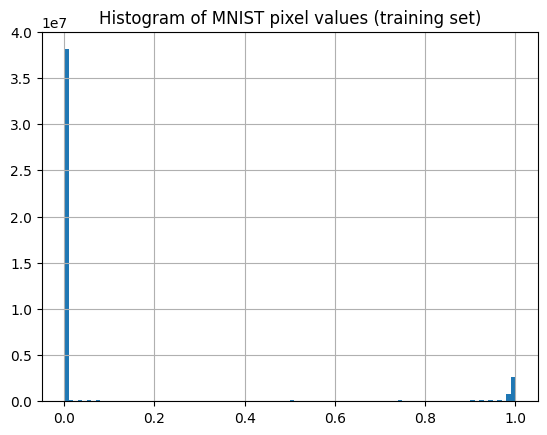

In [ ]:
import math
import matplotlib.pyplot as plt

        
x, _ = next(iter(loader_test))
x = x.to(device)[0:32, :, :, :]

recon_x, mu, logvar = model.forward(x)

d = x[0].numel()
gaussian_nll = (0.5 * ((x - recon_x) ** 2).sum() / x.size(0)) \
               + 0.5 * d * math.log(2 * math.pi)

mse_loss = F.mse_loss(recon_x, x, reduction='mean')

gaussian_from_mse = 0.5 * d * mse_loss + 0.5 * d * math.log(2 * math.pi)

bernoulli_nll = F.binary_cross_entropy(recon_x, x, reduction='sum') / x.size(0)

bce_loss = F.binary_cross_entropy(recon_x, x, reduction='mean')

print('Gaussian distribution')
print(f'Normal log prob: {gaussian_nll:.3f}')
print(f'MSE: {mse_loss:.3f}')
print(f'MSE + constant terms = log prob: {gaussian_from_mse:.3f}')
print(f"|difference|: {abs(gaussian_nll.item() - gaussian_from_mse.item()):.3e}")
print()
print('Bernoulli distribution')
print(f'Bernoulli log prob: {bernoulli_nll:.3f}')
print(f'BCE: {bce_loss:.3f}')

all_train_dataloader = DataLoader(train_dat, len(train_dat))
data = next(iter(all_train_dataloader))
data = data[0].flatten().numpy()
plt.hist(data, bins=100)
plt.grid()
plt.title("Histogram of MNIST pixel values (training set)")

## Part 1.2: Evaluation

### Part 1.2a: Loss curves for different values of beta

Training beta=2
beta=2 | ep 1/20 | train=158.87 test=133.51
beta=2 | ep 2/20 | train=131.40 test=128.45
beta=2 | ep 3/20 | train=127.98 test=125.45
beta=2 | ep 4/20 | train=126.18 test=125.75
beta=2 | ep 5/20 | train=124.96 test=123.32
beta=2 | ep 6/20 | train=123.95 test=123.50
beta=2 | ep 7/20 | train=123.17 test=122.00
beta=2 | ep 8/20 | train=122.61 test=121.44
beta=2 | ep 9/20 | train=121.93 test=120.79
beta=2 | ep 10/20 | train=121.47 test=120.21
beta=2 | ep 11/20 | train=119.92 test=119.26
beta=2 | ep 12/20 | train=119.62 test=118.76
beta=2 | ep 13/20 | train=119.44 test=118.87
beta=2 | ep 14/20 | train=119.19 test=118.43
beta=2 | ep 15/20 | train=118.99 test=118.22
beta=2 | ep 16/20 | train=118.79 test=118.18
beta=2 | ep 17/20 | train=118.61 test=117.83
beta=2 | ep 18/20 | train=118.44 test=117.76
beta=2 | ep 19/20 | train=118.25 test=117.53
beta=2 | ep 20/20 | train=118.03 test=117.58
Training beta=4
beta=4 | ep 1/20 | train=198.22 test=161.58
beta=4 | ep 2/20 | train=158.68 t

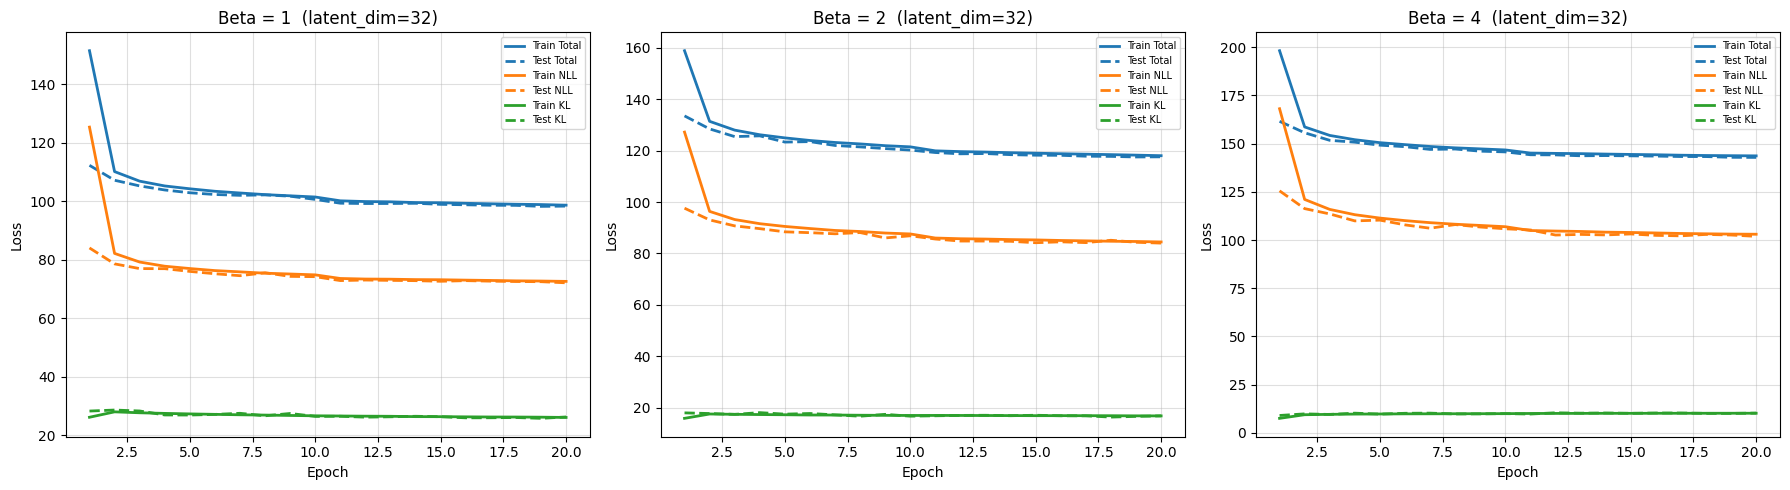

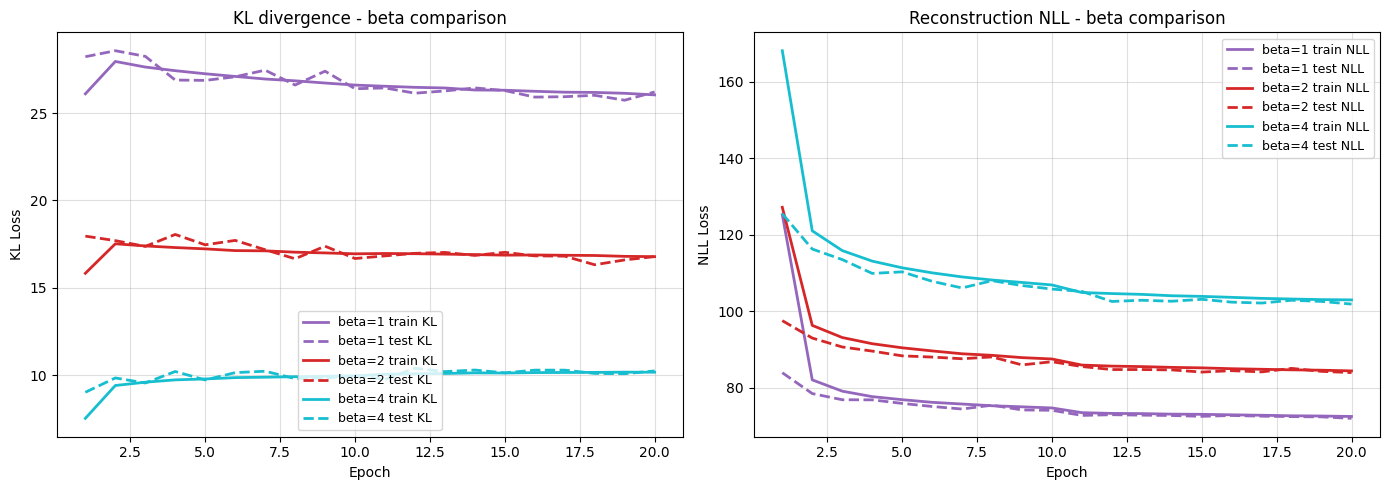

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# train a fresh model for num_epochs with a given beta
def _train_for_beta(bv, n_epochs=20):
    m= VAE(1, latent_dim).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=learning_rate)
    sch = torch.optim.lr_scheduler.StepLR(opt, step_size=lr_step_size, gamma=lr_gamma)
    trl, tel = [], []
    for ep in range(n_epochs):
        # train
        tl, tn, tk = 0., 0., 0.
        m.train()
        for xb, _ in loader_train:
            xb = xb.to(device)
            opt.zero_grad()
            rx, mu, lv = m(xb)
            loss, nll, kld = loss_function_VAE(rx, xb, mu, lv, bv)
            loss.backward(); opt.step()
            tl += loss.item()*xb.size(0); tn += nll.item()*xb.size(0); tk += kld.item()*xb.size(0)
        N_tr = len(loader_train.dataset)
        trl.append([tl/N_tr, tn/N_tr, tk/N_tr])
        # eval
        tl, tn, tk = 0., 0., 0.
        m.eval()
        with torch.no_grad():
            for xb, _ in loader_test:
                xb = xb.to(device)
                rx, mu, lv = m(xb)
                loss, nll, kld = loss_function_VAE(rx, xb, mu, lv, bv)
                tl += loss.item()*xb.size(0); tn += nll.item()*xb.size(0); tk += kld.item()*xb.size(0)
        N_te = len(loader_test.dataset)
        tel.append([tl/N_te, tn/N_te, tk/N_te])
        sch.step()
        print(f'beta={bv} | ep {ep+1}/{n_epochs} | train={trl[-1][0]:.2f} test={tel[-1][0]:.2f}')
    return trl, tel

# beta=1 
_losses_b1_tr = list(train_losses)
_losses_b1_te = list(test_losses)

# train beta=2 and beta=4
print('Training beta=2')
_losses_b2_tr, _losses_b2_te = _train_for_beta(2, n_epochs=20)
print('Training beta=4')
_losses_b4_tr, _losses_b4_te = _train_for_beta(4, n_epochs=20)

all_betas = [1, 2, 4]
all_tr_losses =[_losses_b1_tr, _losses_b2_tr, _losses_b4_tr]
all_te_losses = [_losses_b1_te, _losses_b2_te, _losses_b4_te]

# Figure 1: 3 side-by-side panels, one per beta
curve_colors = ['tab:blue', 'tab:orange', 'tab:green']
curve_names  = ['Total', 'NLL', 'KL']

fig1, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, bv, trl, tel in zip(axes, all_betas, all_tr_losses, all_te_losses):
    tl_arr = np.array(trl)
    te_arr = np.array(tel)
    eps = range(1, len(tl_arr)+1)
    for i, (name, c) in enumerate(zip(curve_names, curve_colors)):
        ax.plot(eps, tl_arr[:, i], color=c, ls='-',  lw=2, label=f'Train {name}')
        ax.plot(eps, te_arr[:, i], color=c, ls='--', lw=2, label=f'Test {name}')
    ax.set_title(f'Beta = {bv}  (latent_dim={latent_dim})', fontsize=12)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(fontsize=7); ax.grid(alpha=0.4)

plt.tight_layout()
plt.show()

# Figure 2: KL comparison across all betas
beta_colors = ['tab:purple', 'tab:red', 'tab:cyan']
fig2, (ax_kl, ax_nll) = plt.subplots(1, 2, figsize=(14, 5))

for bv, bc, trl, tel in zip(all_betas, beta_colors, all_tr_losses, all_te_losses):
    tl_arr= np.array(trl); te_arr = np.array(tel)
    eps = range(1, len(tl_arr)+1)
    ax_kl.plot(eps, tl_arr[:, 2], color=bc, ls='-',  lw=2, label=f'beta={bv} train KL')
    ax_kl.plot(eps, te_arr[:, 2], color=bc, ls='--', lw=2, label=f'beta={bv} test KL')
    ax_nll.plot(eps, tl_arr[:, 1], color=bc, ls='-',  lw=2, label=f'beta={bv} train NLL')
    ax_nll.plot(eps, te_arr[:, 1], color=bc, ls='--', lw=2, label=f'beta={bv} test NLL')

ax_kl.set_title('KL divergence - beta comparison', fontsize=12)
ax_kl.set_xlabel('Epoch'); ax_kl.set_ylabel('KL Loss')
ax_kl.legend(fontsize=9); ax_kl.grid(alpha=0.4)

ax_nll.set_title('Reconstruction NLL - beta comparison', fontsize=12)
ax_nll.set_xlabel('Epoch'); ax_nll.set_ylabel('NLL Loss')
ax_nll.legend(fontsize=9); ax_nll.grid(alpha=0.4)
plt.tight_layout()
plt.show()

### Part 1.2b: Samples and reconstructions

Input images
--------------------------------------------------
Reconstructed images
--------------------------------------------------
Generated Images
--------------------------------------------------


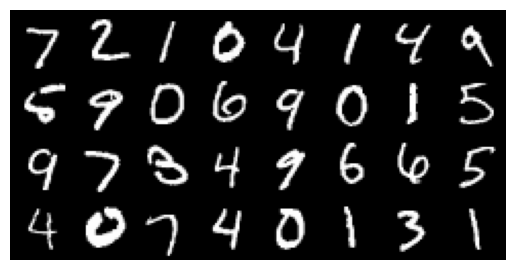

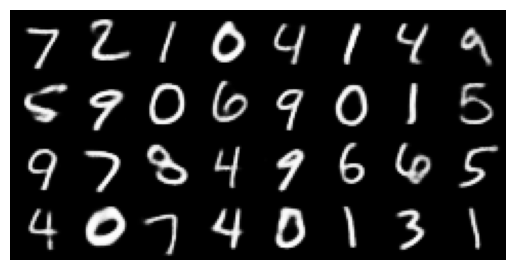

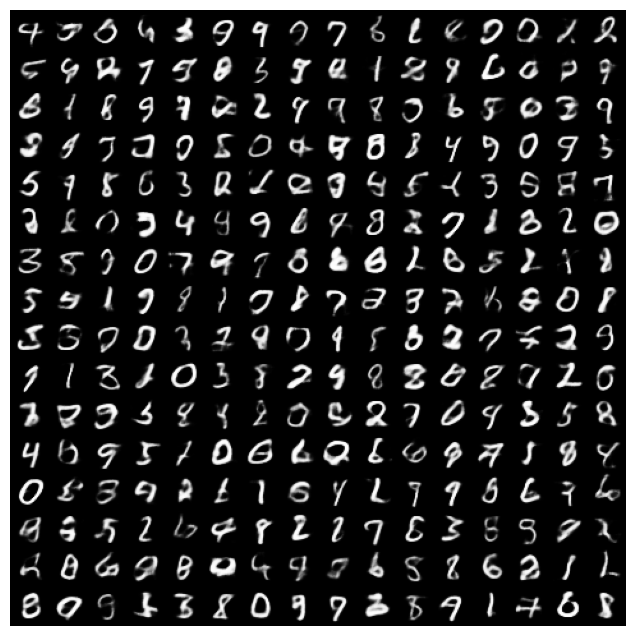

In [ ]:
# load the model
print('Input images')
print('-'*50)

sample_inputs, _ = next(iter(loader_test))
fixed_input = sample_inputs[0:32, :, :, :]
# visualize the original images of the last batch of the test set
img = make_grid(denorm(fixed_input), nrow=8, padding=2, normalize=False,
                scale_each=False, pad_value=0)
plt.figure()
show(img)

print('Reconstructed images')
print('-'*50)
model.eval()
with torch.no_grad():
    # visualize the reconstructed images of the last batch of test set
    
    recon_batch, _, _ = model(fixed_input.to(device))
    
    recon_batch = recon_batch.cpu()
    recon_batch = make_grid(denorm(recon_batch), nrow=8, padding=2, normalize=False,
                             scale_each=False, pad_value=0)
    plt.figure()
    show(recon_batch)

print('Generated Images')  
print('-'*50)
model.eval()
n_samples = 256
z = torch.randn(n_samples,latent_dim).to(device)
with torch.no_grad():
    samples = model.decode(z)
    
    samples = samples.cpu()
    samples = make_grid(denorm(samples), nrow=16, padding=2, normalize=False,
                             scale_each=False, pad_value=0)
    plt.figure(figsize = (8,8))
    show(samples)

### Discussion

**What do you observe in the behaviour of the log-likelihood loss and the KL loss (increasing/decreasing)?**

The NLL decreases strongly and consistently across all three beta values. For beta=1, the total ELBO loss falls from 151.40 at epoch 0 to 98.61 by epoch 19, with the NLL component converging to approximately 73. For beta=2, the total loss decreases from 158.87 to 118.03, with NLL settling near 84. For beta=4, the total loss drops from 198.22 to 143.67, with NLL converging to roughly 103. In all cases the steepest drop occurs within the first two to three epochs, followed by a slower and steadier decline. The learning rate reduction from 0.001 to 0.0005 at epoch 10 via the StepLR scheduler produces a visible secondary drop, most clearly seen in the beta=1 curves, after which convergence tightens further. Train and test losses track each other closely throughout, indicating no meaningful overfitting.

The KL behaviour differs by beta and is not uniformly monotone. For beta=1, the KL begins high at approximately 28 in the first epoch and drifts mildly downward to stabilise around 26 by epoch 20. For beta=2, it starts near 18 and stabilises around 17. For beta=4, the KL actually starts lower at around 8 to 9 in the first epoch and rises slightly before stabilising near 10. The correct overall characterisation is therefore that the NLL decreases strongly while the KL quickly enters a stable regime after the first few epochs, with its equilibrium level being inversely related to beta. Higher beta penalises the KL term more heavily in the loss NLL + beta * KLD, which pushes the approximate posterior `q(z|x)` more aggressively toward the prior `N(0,I)`, resulting in a lower stable KL at the cost of a higher converged NLL.

**Can you intuitively explain if this behaviour is desirable?**

Yes, this is the expected and healthy behaviour for a beta-VAE. The strongly decreasing NLL confirms the decoder is learning to reconstruct inputs more faithfully over time, increasing the log-likelihood of the data under the model. Crucially, the KL stabilising at a clearly non-trivial positive value throughout training is an important sign of health: it means the encoder is actively using the latent dimensions to encode input-specific information rather than collapsing to the prior. A KL that stays meaningfully above zero confirms that the approximate posterior genuinely differs from the prior and that the latent code carries useful structure about the input.

The trade-off introduced by increasing beta is visible directly in the numbers. At beta=4 the NLL at convergence is approximately 103, compared to 84 for beta=2 and 73 for beta=1. Higher beta forces the posterior closer to the isotropic Gaussian prior, producing a smoother and more generative-friendly latent space since samples drawn from p(z) = N(0,I) at test time will land in regions the decoder has been trained on. This comes at the cost of reconstruction sharpness, as the encoder is constrained to discard some input-specific detail to satisfy the stronger regularisation. This trade-off is fully consistent with the beta-VAE framework described in the lecture slides, where the ELBO balances the reconstruction term against the KL regulariser.

**What is posterior collapse and did you observe it during training (i.e. when the KL is too small during the early stages of training)?**

Posterior collapse is a failure mode in VAE training where the encoder learns to ignore the input entirely for one or more latent dimensions, causing those dimensions to map directly onto the prior so that `q(z_i|x)` collapses to `p(z_i)` = `N(0,1)`. The KL contribution from those dimensions falls to zero, and the decoder effectively learns to reconstruct without using them. The practical consequences are wasted latent capacity, reduced diversity in generated samples, and blurry or mode-averaged outputs, since the decoder for those dimensions is operating as if conditioned on noise drawn straight from the prior with no input information. This pathology is most likely to occur in the early stages of training when the gradient from the KL penalty dominates before the decoder has built up a strong reconstruction signal, making it cheaper for the optimiser to collapse the posterior than to learn a meaningful encoding.

Posterior collapse was not observed in these experiments. The KL values are non-trivial from the very first epoch across all beta values and never approach zero at any stage of training. For beta=4 specifically, the KL begins at around 8 to 9 and rises slightly to stabilise near 10, which is the opposite dynamic to collapse and shows the encoder building up its use of the latent space even under the strongest regularisation applied here. The NLL decreases consistently in parallel, which would not be the case if the decoder were ignoring z and functioning as an unconditional model.

Several factors explain why collapse was avoided. MNIST is a relatively simple and well-structured dataset, so the reconstruction loss provides a strong and immediate gradient signal to the encoder from the very first update steps, keeping the latent code informative before the KL term can dominate. The Bernoulli BCE likelihood used in the implementation is also well-matched to the near-binary nature of MNIST pixels, as confirmed by the pixel histogram showing heavy concentration at 0 and 1 with very little mass in between. This means the reconstruction loss is sharp and informative throughout training rather than being washed out by a mismatched likelihood function. Additionally, the latent dimensionality of 32 is reasonably proportioned to the complexity of MNIST, so there is no strong gradient pressure for the encoder to discard dimensions wholesale. These factors together kept the KL at healthy non-zero values across all beta settings, making explicit remedies such as KL annealing unnecessary.

## Part 1.3: Latent space exploration

In [ ]:
from sklearn.manifold import TSNE

test_dataloader = DataLoader(test_dat, 100, shuffle=False)

z_list, y_list = [], []
model.eval()
with torch.no_grad():
    for imgs, lbls in test_dataloader:
        imgs = imgs.to(device)
        mu, logvar = model.encode(imgs)
        z_list.append(mu.cpu().numpy())
        y_list.append(lbls.numpy())

z_all = np.concatenate(z_list, axis=0)
y = np.concatenate(y_list, axis=0)

print('Performing TSNE')
z_embedded_5  = TSNE(n_components=2, perplexity=5,random_state=0).fit_transform(z_all)
z_embedded_30 = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(z_all)
z_embedded_50 = TSNE(n_components=2, perplexity=50, random_state=0).fit_transform(z_all)

Performing TSNE


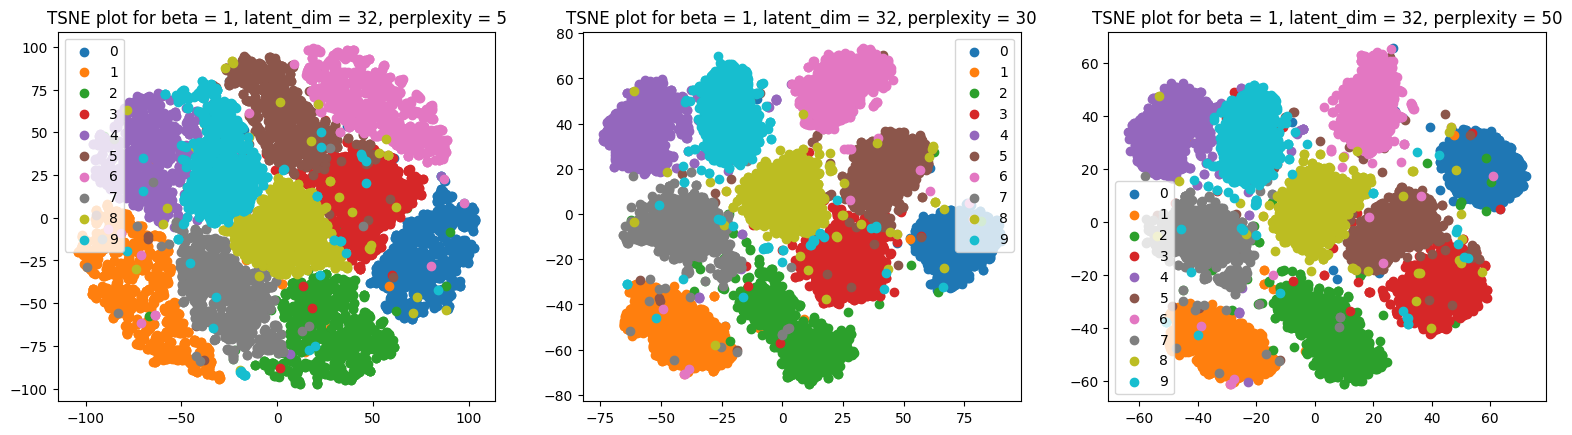

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(19.2, 4.8))
labels = [5, 30, 50]
z_list = [z_embedded_5, z_embedded_30, z_embedded_50]
for i in range(len(labels)):
    for digit in np.unique(y):
        idx = np.where(y == digit)
        ax[i].scatter(z_list[i][idx,0], z_list[i][idx,1], label=digit)
    ax[i].legend()
    ax[i].set_title(f'TSNE plot for beta = {beta}, latent_dim = {latent_dim}, perplexity = {labels[i]}')

Training VAE for beta=1:
Training VAE for beta=2:
Training VAE for beta=5:
Performing T-SNE for beta=1
perplexity=5
perplexity=30
perplexity=50
Performing T-SNE for beta=2
perplexity=5
perplexity=30
perplexity=50
Performing T-SNE for beta=5
perplexity=5
perplexity=30
perplexity=50


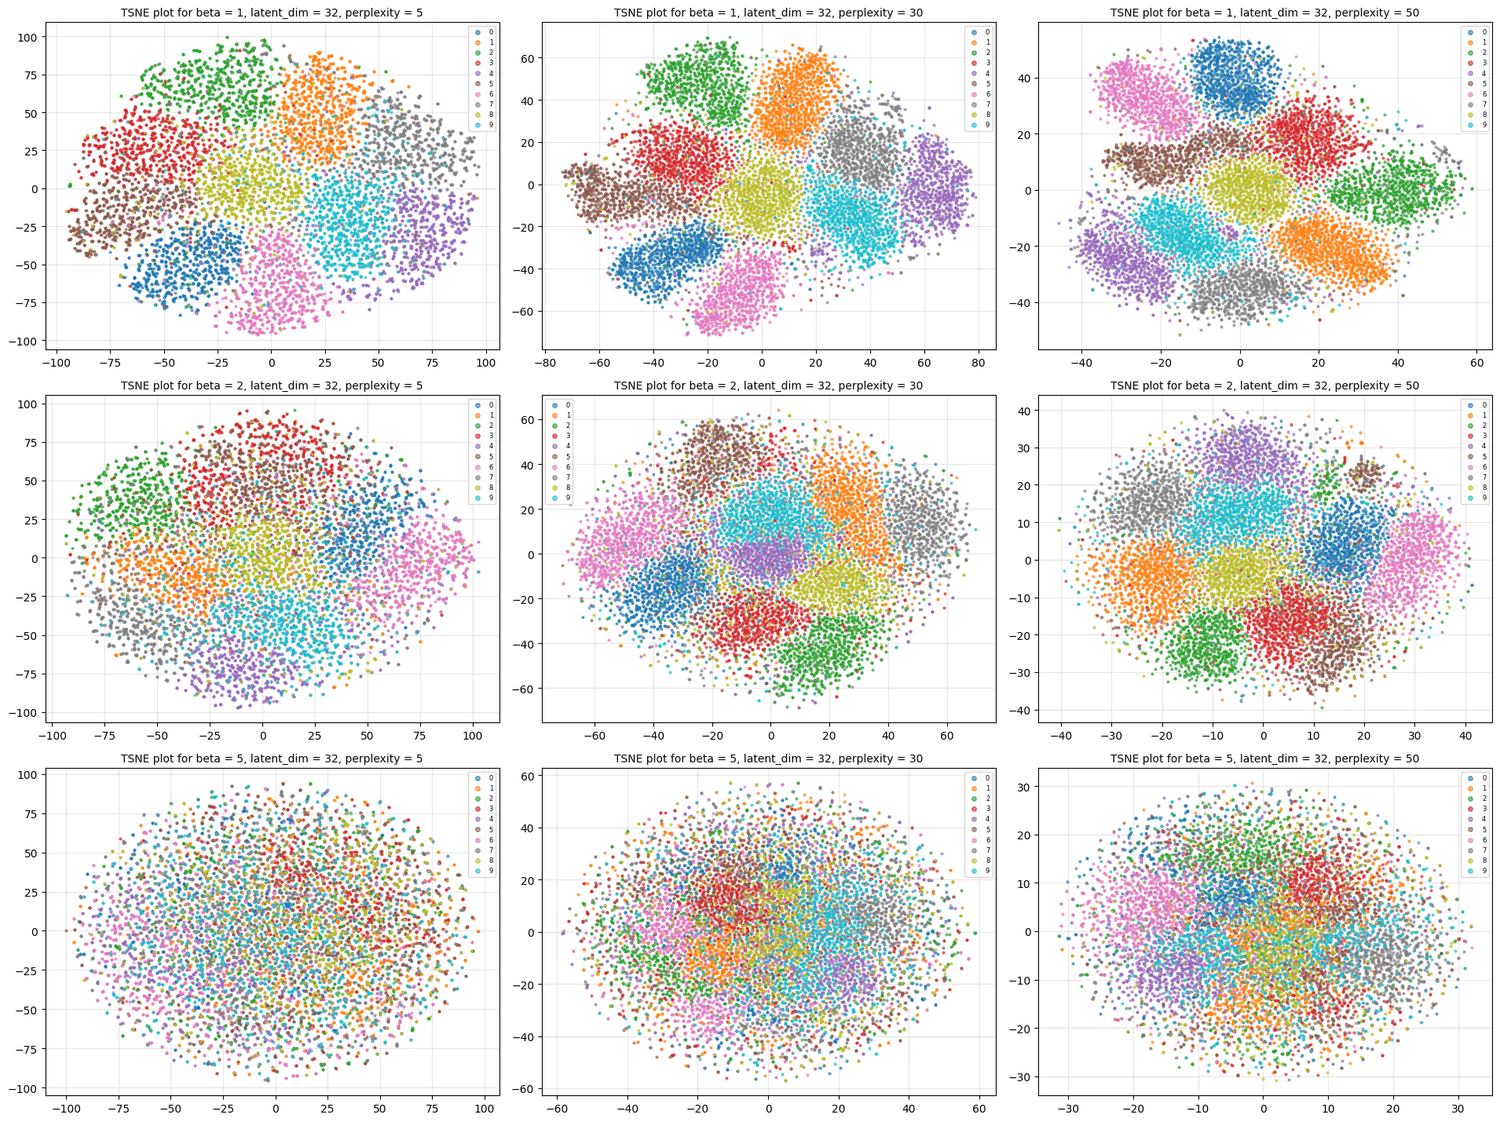

In [ ]:
from sklearn.manifold import TSNE

_betas_tsne = [1, 2, 5]
_perps_tsne = [5, 30, 50]
_n_epochs_tsne = 25
_n_test_tsne= 10000 

def _tsne_train(bv, n_epochs):
    """Train a fresh VAE with given beta, return trained model."""
    m   = VAE(1, latent_dim).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=learning_rate)
    sch = torch.optim.lr_scheduler.StepLR(
              opt, step_size=lr_step_size, gamma=lr_gamma)
    for ep in range(n_epochs):
        m.train()
        for xb, _ in loader_train:
            xb = xb.to(device)
            opt.zero_grad()
            rx, mu, lv = m(xb)
            loss, _, _ = loss_function_VAE(rx, xb, mu, lv, bv)
            loss.backward()
            opt.step()
        sch.step()
        print(f'beta={bv} | epoch {ep+1}', end='\r')
    return m

# train one model per beta and store in dict
_models_tsne = {}
for bv in _betas_tsne:
    print(f'Training VAE for beta={bv}:')
    _models_tsne[bv] = _tsne_train(bv, _n_epochs_tsne)

_tsne_loader = DataLoader(test_dat, _n_test_tsne, shuffle=False)

fig, axes = plt.subplots(len(_betas_tsne), len(_perps_tsne),
                         figsize=(19.2, len(_betas_tsne) * 4.8))

for row, bv in enumerate(_betas_tsne):
    latents, labels_tsne = [], []
    _models_tsne[bv].eval()
    with torch.no_grad():
        for x, y in _tsne_loader:
            x = x.to(device)
            mu, logvar = _models_tsne[bv].encode(x)
            z = _models_tsne[bv].reparametrize(mu, logvar)
            latents.append(z.cpu().numpy())
            labels_tsne.append(y.cpu().numpy())
    latent_vectors = np.concatenate(latents, axis=0)
    labels_arr     = np.concatenate(labels_tsne, axis=0)

    print(f'Performing T-SNE for beta={bv}')
    z_embedded = {}
    for perp in _perps_tsne:
        print(f'perplexity={perp}')
        z_embedded[perp] = TSNE(
            n_components=2, perplexity=perp, random_state=42
        ).fit_transform(latent_vectors)

    # plot one row per beta
    for col, perp in enumerate(_perps_tsne):
        ax = axes[row][col]
        for digit in np.unique(labels_arr):
            idx = np.where(labels_arr == digit)
            ax.scatter(z_embedded[perp][idx, 0],
                       z_embedded[perp][idx, 1],
                       label=digit, s=4, alpha=0.6)
        ax.legend(fontsize=6, markerscale=2)
        ax.set_title(
            f'TSNE plot for beta = {bv}, '
            f'latent_dim = {latent_dim}, '
            f'perplexity = {perp}',
            fontsize=10
        )
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Part 1.3b: Interpolating in z

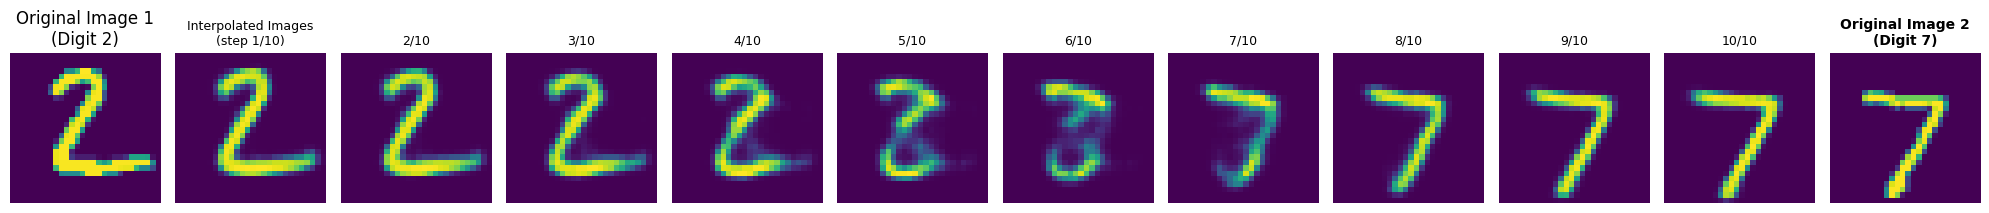

In [ ]:
num_steps = 10

# pick digit-2 and digit-7 from test set (must be different labels)
test_imgs, test_labels = next(iter(DataLoader(test_dat, 512, shuffle=False)))
idx1 = (test_labels == 2).nonzero(as_tuple=True)[0][0].item()
idx2 = (test_labels == 7).nonzero(as_tuple=True)[0][0].item()

image1 = test_imgs[idx1:idx1+1]
image2 = test_imgs[idx2:idx2+1]

model.eval()
with torch.no_grad():
    mu1, _ = model.encode(image1.to(device))
    mu2, _ = model.encode(image2.to(device))

# linear interpolation: z = (1-a)*mu1 + a*mu2
alphas = torch.linspace(0, 1, num_steps).to(device)
interpolated_embeddings = torch.stack(
    [(1 - a) * mu1 + a * mu2 for a in alphas], dim=0
).squeeze(1)   # (num_steps, latent_dim)

with torch.no_grad():
    interpolated_images = model.decode(interpolated_embeddings)

image1 = denorm(image1)
image2 = denorm(image2)

def imshow(img, ax):
    img = img.permute(1, 2, 0)
    ax.imshow(img.cpu().numpy())
    ax.axis('off')

fig, axes = plt.subplots(1, interpolated_images.size(0) + 2, figsize=(20, 5))

imshow(image1[0], axes[0])
axes[0].set_title('Original Image 1\n(Digit 2)')

for i in range(interpolated_images.size(0)):
    imshow(interpolated_images[i], axes[i + 1])
    if i == 0:
        axes[i + 1].set_title(f'Interpolated Images\n(step {i+1}/{num_steps})', fontsize=9)
    else:
        axes[i + 1].set_title(f'{i+1}/{num_steps}', fontsize=9)

imshow(image2[0], axes[-1])
axes[-1].set_title('Original Image 2\n(Digit 7)', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(content_path/'CW_VAE/latent_interpolation.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 1.4: Hot dog generation

In [ ]:
# Now let's adapt our VAE for hot dog image generation
# The DLHotDogDataset class will automatically download and prepare the dataset
# Since our VAE architecture is relatively simple, we'll start with the same 
# resolution as MNIST (28x28) to establish a baseline
# Note this can take a while to load

# Define image parameters
image_size = 28  # Same size as MNIST for initial experiments
batch_size = 64  # Process 64 images at a time

# Define training data transforms
# - ToTensor: Convert PIL images to tensors and scale to [0,1]
# - Normalize: Rescale to [-1,1] using mean=(0.5,0.5,0.5) and std=(0.5,0.5,0.5)
# - Resize: Scale images to 28x28
# - Random flips: Data augmentation to help prevent overfitting
transform_ = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
     transforms.Resize((image_size, image_size)),
     transforms.RandomHorizontalFlip(p=0.5),
     transforms.RandomVerticalFlip(p=0.5)]
     )

# Define test data transforms - same as training but without augmentation
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    transforms.Resize((image_size, image_size)),
])

# Create train and test datasets
hotdogdata_train = DLHotDogDataset(root=data_path, transform=transform_, split='train')
hotdogdata_test = DLHotDogDataset(root=data_path, transform=transform_test, split='test')

# Create data loaders for batched processing
# Shuffle training data but keep test data ordered
hotdogdata_loader_train = DataLoader(hotdogdata_train, batch_size, shuffle=True)
hotdogdata_loader_test = DataLoader(hotdogdata_test, batch_size, shuffle=False)

# Save a batch of original test images for later comparison
# Takes first 32 images from test set
sample_inputs_, _ = next(iter(hotdogdata_loader_test))
fixed_input_ = sample_inputs_[:32, :, :, :]
save_image(fixed_input_, content_path/'CW_VAE/image_original_hd.png')

number of hot dogs:  9000
number of hot dogs:  1000


### Part 1.4a: Train the VAE

In [ ]:
class VAE_HD(VAE):
    """Same VAE but with Tanh output — for data normalised to [-1, 1]."""
    def __init__(self, channels, latent_dim):
        super().__init__(channels, latent_dim)
        layers = list(self.decoder.children())
        layers[-1] = nn.Tanh()
        self.decoder = nn.Sequential(*layers)

# more training than for MNIST
num_epochs = 60

def loss_function_VAE(recon_x, x, mu, logvar, beta):
        NLL = F.mse_loss(recon_x, x, reduction='sum') / x.size(0)
        
        KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
        
        return NLL + beta * KLD, NLL, KLD

model = VAE_HD(3, latent_dim).to(device)
model_path = content_path/f"CW_VAE/VAE_hd_model_{latent_dim}.pth"

# set to True to continue training from a previous run
load_checkpoint = False
if os.path.exists(model_path) and load_checkpoint:
    print("loading existing model...")
    model.load_state_dict(torch.load(model_path))
    
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
train_losses = []
test_losses = []
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size = lr_step_size, gamma = lr_gamma)
for epoch in range(num_epochs):     
        total_loss, total_NLL_loss, total_KLD_loss = 0, 0, 0
        model.train()
        for data, y in hotdogdata_loader_train:
            data = data.to(device)
            optimizer.zero_grad()
            recon, mu, logvar = model(data)
            loss, nll, kld = loss_function_VAE(recon, data, mu, logvar, beta)
            loss.backward()
            optimizer.step()
            total_loss     += loss.item() * data.size(0)
            total_NLL_loss += nll.item()  * data.size(0)
            total_KLD_loss += kld.item()  * data.size(0)
        train_losses.append([total_loss     / len(hotdogdata_loader_train.dataset),
                             total_NLL_loss / len(hotdogdata_loader_train.dataset),
                             total_KLD_loss / len(hotdogdata_loader_train.dataset)])
        
        total_loss, total_NLL_loss, total_KLD_loss = 0, 0, 0
        model.eval()
        with torch.no_grad():
            for data, y in hotdogdata_loader_test:
                data = data.to(device)
                recon, mu, logvar = model(data)
                loss, nll, kld = loss_function_VAE(recon, data, mu, logvar, beta)
                total_loss     += loss.item() * data.size(0)
                total_NLL_loss += nll.item()  * data.size(0)
                total_KLD_loss += kld.item()  * data.size(0)
        test_losses.append([total_loss     / len(hotdogdata_loader_test.dataset),
                            total_NLL_loss / len(hotdogdata_loader_test.dataset),
                            total_KLD_loss / len(hotdogdata_loader_test.dataset)])
        lr = optimizer.param_groups[0]['lr']
        print(f'Epoch: {epoch}, train loss = {train_losses[-1][0]:.4f}, '
              f'test={test_losses[-1][0]:.4f}, lr={lr:.6f}')
        scheduler.step()
        # save the model
        if epoch % 5 == 0:
            with torch.no_grad():
                torch.save(model.state_dict(), model_path)
                
        if epoch == num_epochs - 1:
            with torch.no_grad():
                torch.jit.save(torch.jit.trace(model, (data), check_trace=False),
                    content_path/'CW_VAE/VAE_hd_model_jit.pth')

[... earlier log lines omitted ...]
Epoch: 20, train loss = 308.4772, test=305.6483, lr=0.000250
Epoch: 21, train loss = 307.5082, test=305.7336, lr=0.000250
Epoch: 22, train loss = 307.1952, test=305.2102, lr=0.000250
Epoch: 23, train loss = 306.9364, test=305.9195, lr=0.000250
Epoch: 24, train loss = 306.8462, test=305.1220, lr=0.000250
Epoch: 25, train loss = 306.7468, test=304.8750, lr=0.000250
Epoch: 26, train loss = 306.4056, test=304.4898, lr=0.000250
Epoch: 27, train loss = 306.2249, test=304.3200, lr=0.000250
Epoch: 28, train loss = 305.9367, test=304.3482, lr=0.000250
Epoch: 29, train loss = 305.9697, test=304.6336, lr=0.000250
Epoch: 30, train loss = 304.5426, test=302.7173, lr=0.000125
Epoch: 31, train loss = 303.9167, test=302.8268, lr=0.000125
Epoch: 32, train loss = 303.8763, test=302.6086, lr=0.000125
Epoch: 33, train loss = 303.7692, test=302.9263, lr=0.000125
Epoch: 34, train loss = 303.5583, test=302.5346, lr=0.000125
Epoch: 35, train loss = 303.3332, test=302.8517, 

### Part 1.4b: Sample visualisation

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0000004..0.9944164].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9685515..0.94419616].


Input images
--------------------------------------------------
Reconstructed images
--------------------------------------------------
Generated Images
--------------------------------------------------


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9830013..0.9776509].


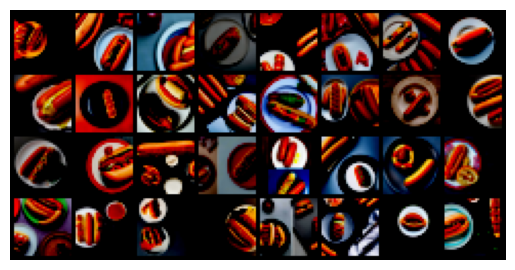

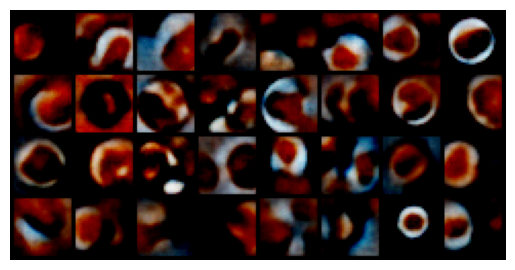

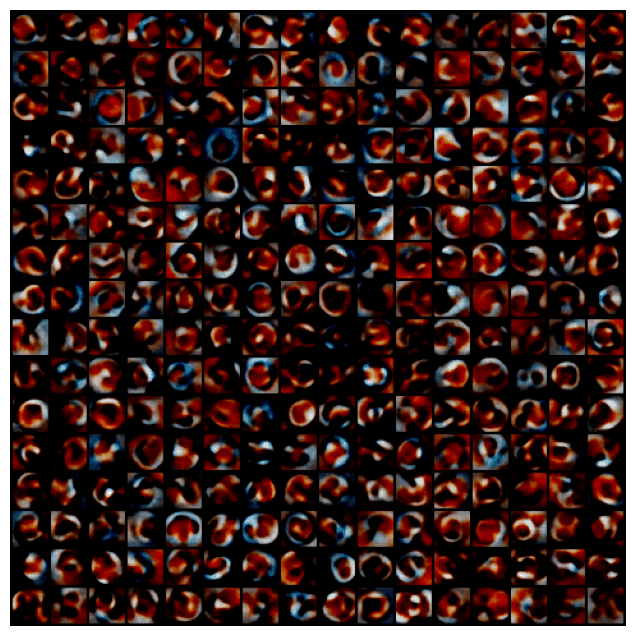

In [ ]:
# load the model
print('Input images')
print('-'*50)

sample_inputs, _ = next(iter(hotdogdata_loader_test))
fixed_input = sample_inputs[0:32, :, :, :]
# visualize the original images of the last batch of the test set
img = make_grid(denorm(fixed_input), nrow=8, padding=2, normalize=False,
                scale_each=False, pad_value=0)
plt.figure()
show(img)

print('Reconstructed images')
print('-'*50)
model.eval()
with torch.no_grad():
    # visualize the reconstructed images of the last batch of test set
    
    recon_batch, _, _ = model(fixed_input.to(device))
    
    recon_batch = recon_batch.cpu()
    recon_batch = make_grid(denorm(recon_batch), nrow=8, padding=2, normalize=False,
                            scale_each=False, pad_value=0)
    plt.figure()
    show(recon_batch)

print('Generated Images')  
print('-'*50)
model.eval()
n_samples = 256
z = torch.randn(n_samples,latent_dim).to(device)
with torch.no_grad():
    samples = model.decode(z)
    
    samples = samples.cpu()
    samples = make_grid(denorm(samples), nrow=16, padding=2, normalize=False,
                        scale_each=False, pad_value=0)
    plt.figure(figsize = (8,8))
    show(samples)

### Part 1.4c: Interpolating in z

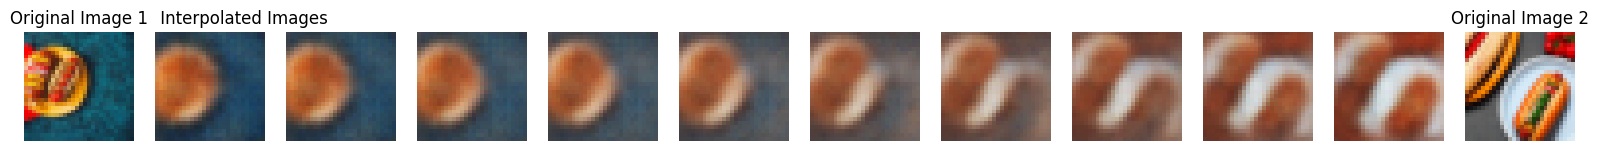

In [ ]:
num_steps = 10

model.eval()
hd_imgs, _ = next(iter(hotdogdata_loader_test))
image1 = hd_imgs[0:1]
image2 = hd_imgs[1:2]

with torch.no_grad():
    mu1, _ = model.encode(image1.to(device))
    mu2, _ = model.encode(image2.to(device))

alphas = torch.linspace(0, 1, num_steps).to(device)
interpolated_embeddings = torch.stack(
    [(1 - a) * mu1 + a * mu2 for a in alphas], dim=0
).squeeze(1)

with torch.no_grad():
    interpolated_images = model.decode(interpolated_embeddings)

# denorm for display
interpolated_images = denorm_hd(interpolated_images).clamp(0, 1).cpu()
image1 = denorm_hd(image1).clamp(0, 1)
image2 = denorm_hd(image2).clamp(0, 1)

def imshow(img, ax):
    img = img.permute(1, 2, 0)
    ax.imshow(img.cpu().numpy())
    ax.axis('off')

fig, axes = plt.subplots(1, interpolated_images.size(0) + 2, figsize=(20, 5))
imshow(image1[0], axes[0])
axes[0].set_title('Original Image 1')
for i in range(interpolated_images.size(0)):
    imshow(interpolated_images[i], axes[i + 1])
axes[1].set_title('             Interpolated Images')
imshow(image2[0], axes[-1])
axes[-1].set_title('Original Image 2')
plt.show()

The reconstructions and samples are poor at this resolution, so a pretrained VAE is used in Part 2.

# Part 2: Denoising Diffusion Probabilistic Model (DDPM)

In [ ]:
import sys
!{sys.executable} -m pip install -U "huggingface_hub>=0.27.0" "diffusers>=0.36.0" "transformers>=4.45.0" "accelerate>=0.30.0"

In [ ]:
import os 
# We specified data path in part 1
cache_path = os.path.join(data_path, "cache")
print('Caching models in', cache_path)
%env XDG_CACHE_HOME=cache_path
%env HF_HOME=cache_path

import torch 
from PIL import Image
from torchvision import transforms
from diffusers import AutoencoderKL
import matplotlib.pyplot as plt 
from torch.optim import Adam
from typing import Dict, Tuple
from tqdm import tqdm

from torchvision import transforms
import numpy as np
from typing import Any, Callable, Optional, Tuple, Union
from pathlib import Path

Caching models in ./dl/data/cache
env: XDG_CACHE_HOME=cache_path
env: HF_HOME=cache_path


### Loading a pretrained VAE from Hugging Face

In [ ]:
from huggingface_hub import login

# Hugging Face access token: provide it through the HF_TOKEN environment variable (never hard-code it)
hf_token = os.environ.get("HF_TOKEN")
if hf_token:
    login(token=hf_token)

A wrapper for Stable Diffusion's VAE:

In [ ]:
class VAE: 
    def __init__(self, device="cuda") -> None:
        vae = AutoencoderKL.from_pretrained(
            "Manojb/stable-diffusion-2-base", subfolder="vae",
        )

        vae = vae.to(device)
        self.vae = vae

    def __call__(self, x):
        # assumes 0-1 normalized image
        single_image = False
        if len(x.size()) == 3: 
            single_image = True
            x = x.unsqueeze(dim=0)
        
        if x.min() >= 0: 
            x = x * 2 - 1 

        with torch.no_grad():
            encode = self.vae.encode(x.cuda())
            batch = encode.latent_dist.sample() *  self.vae.config.scaling_factor
        if single_image: 
            batch = batch.squeeze(dim=0)
        return batch

    def encode(self, x): 
        return self(x)
    
    def decode(self, z): 
        """
        returns: decode image"""
        if len(z.size()) == 3: 
            z = z.unsqueeze(dim=0)
        with torch.no_grad():
            x = self.vae.decode(z / self.vae.config.scaling_factor, return_dict=False)[0]

        x = ((1 + x) * 0.5).clip(0, 1)
        return x

sd_vae = VAE()

## Part 2.1: Exploring the Stable Diffusion VAE

In [ ]:
# Import required libraries for dataset handling
from icl_dl_cw2_utils.utils.hotdogdataset import DLHotDogDataset
from torch.utils.data import DataLoader

# Define image size and batch size parameters
# Using larger images since we don't need to train the VAE anymore
image_size_ = 112  # Target image size after transforms
batch_size = 32    # Number of images per batch

# Define image transformations for training data
# First resize to 128 then center crop to ensure consistent sizing
transform_ = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(image_size_),
    transforms.ToTensor()
])

# Define image transformations for test data
transform_test_ = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((image_size_, image_size_))
])

# Load training and test datasets with the defined transforms
hotdogdata_train_256 = DLHotDogDataset(root=data_path, transform=transform_, split='train', preload=True)
hotdogdata_test_256 = DLHotDogDataset(root=data_path, transform=transform_, split='test', preload=True)

# Create data loaders for efficient batching
# num_workers=8 enables parallel data loading
hotdogdata_loader_train_112 = DataLoader(hotdogdata_train_256, batch_size, shuffle=True, num_workers=8)
hotdogdata_loader_test_112 = DataLoader(hotdogdata_test_256, batch_size, shuffle=True, num_workers=8)

# Get a batch of test images to verify dimensions
data_iter = iter(hotdogdata_loader_test_112)
images, _ = next(data_iter)
print(f"Batch shape: {images.shape} (batch_size, channels, height, width)")

# Calculate and display dataset statistics
hotdogdata_mean, hotdogdata_std_dev = hotdogdata_train_256.calculate_mean_and_std()
print(f'Dataset statistics:')
print(f'Mean pixel value: {hotdogdata_mean:.4f}')
print(f'Standard deviation: {hotdogdata_std_dev:.4f}')

number of hot dogs:  9000
number of hot dogs:  1000


Batch shape: torch.Size([32, 3, 112, 112]) (batch_size, channels, height, width)
Dataset statistics:
Mean pixel value: 0.4591
Standard deviation: 0.3086


### Part 2.1a: Interpolating in z

Loaded batch of images with shape: torch.Size([32, 3, 112, 112])
Individual image shape: torch.Size([1, 3, 112, 112])
Latent embedding shape: torch.Size([1, 4, 14, 14])
Shape of interpolated embeddings: torch.Size([10, 4, 14, 14])
Shape of decoded interpolated images: torch.Size([10, 3, 112, 112])


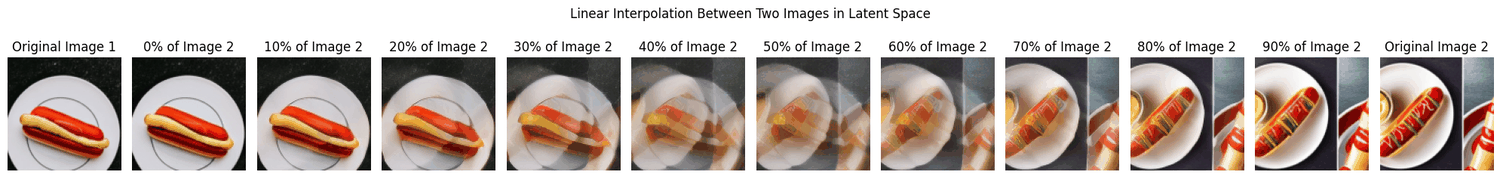

In [ ]:
from icl_dl_cw2_utils.utils.hotdogdataset import DLHotDogDataset
# This code demonstrates how to:
# 1. Take two images from the dataset
# 2. Encode them into the latent space
# 3. Create interpolated points between their latent representations
# 4. Decode the interpolated points back to images

num_steps = 10

data_iter = iter(hotdogdata_loader_train_112)
images, _ = next(data_iter)
print(f"Loaded batch of images with shape: {images.shape}")

# Select first two images and move to device
image1 = images[0:1].to(device)
image2 = images[1:2].to(device)
print(f"Individual image shape: {image1.shape}")

# Encode images to latent space
with torch.no_grad():
    z1 = sd_vae.encode(image1)
    z2 = sd_vae.encode(image2)
    print(f"Latent embedding shape: {z1.shape}")

alphas = torch.linspace(0, 1, num_steps).to(device)

interpolated_embeddings = torch.stack([
    (1 - alpha) * z1 + alpha * z2 for alpha in alphas
]).squeeze(1)
print(f"Shape of interpolated embeddings: {interpolated_embeddings.shape}")    

with torch.no_grad():
    interpolated_images = sd_vae.decode(interpolated_embeddings)
    print(f"Shape of decoded interpolated images: {interpolated_images.shape}")

def imshow(img, ax):
    """Display an image on the given matplotlib axis"""
    img = img.squeeze().permute(1, 2, 0)
    ax.imshow(img.cpu().numpy())
    ax.axis('off')

fig, axes = plt.subplots(1, interpolated_images.size(0) + 2, figsize=(20, 5))

imshow(image1, axes[0])
axes[0].set_title('Original Image 1')

# Show interpolated images
for i in range(interpolated_images.size(0)):
    imshow(interpolated_images[i], axes[i + 1])
    axes[i + 1].set_title(f'{i*10}% of Image 2')

# Show second original image
imshow(image2, axes[-1])
axes[-1].set_title('Original Image 2')

plt.suptitle('Linear Interpolation Between Two Images in Latent Space', y=0.75)
plt.tight_layout()
plt.show()

### Part 2.1b: Sample visualisation


1. Displaying Original Input Images from Test Set
----------------------------------------------------------------------

2. Displaying VAE Reconstructions
----------------------------------------------------------------------
The VAE should learn to accurately reconstruct the input images

3. Displaying Generated Images from Random Noise
----------------------------------------------------------------------
The VAE should generate plausible new images from random latent vectors
Latent embedding shape: torch.Size([32, 4, 14, 14])


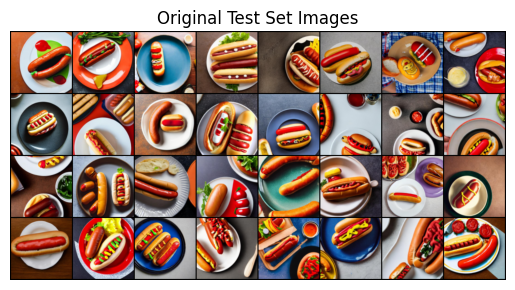

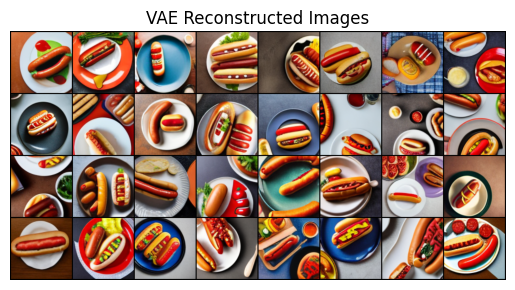

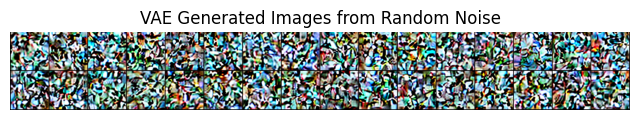

In [ ]:
# This section demonstrates reconstruction and generation capabilities of the trained VAE

from torchvision.utils import save_image, make_grid

# Helper function to denormalize images if needed
def denorm(x):
    return x

# 1. Visualize Input Images
print('\n1. Displaying Original Input Images from Test Set')
print('-'*70)
sample_inputs, _ = next(iter(hotdogdata_loader_test_112))
fixed_input = sample_inputs[0:32, :, :, :]
input_grid = make_grid(denorm(fixed_input), nrow=8, padding=2, normalize=False,
                      scale_each=False, pad_value=0)
plt.figure()
plt.title('Original Test Set Images')
show(input_grid)

# 2. Visualize Reconstructed Images
print('\n2. Displaying VAE Reconstructions')
print('-'*70)
print('The VAE should learn to accurately reconstruct the input images')

with torch.no_grad():
    fixed_input_device = fixed_input.to(device)
    
    recon_emb = sd_vae.encode(fixed_input_device)
    
    recon_batch = sd_vae.decode(recon_emb)
    
    recon_grid = make_grid(denorm(recon_batch.cpu()), nrow=8, padding=2, normalize=False,
                          scale_each=False, pad_value=0)
    plt.figure()
    plt.title('VAE Reconstructed Images')
    show(recon_grid)

# 3. Generate New Images from Random Noise
print('\n3. Displaying Generated Images from Random Noise')
print('-'*70)
print('The VAE should generate plausible new images from random latent vectors')

n_samples = 256
print(f'Latent embedding shape: {recon_emb.shape}')
z = torch.randn_like(recon_emb).to(device)

with torch.no_grad():
    samples = sd_vae.decode(z)
    
    samples_grid = make_grid(denorm(samples.cpu()), nrow=16, padding=2, normalize=False,
                           scale_each=False, pad_value=0)
    plt.figure(figsize=(8,8))
    plt.title('VAE Generated Images from Random Noise')
    show(samples_grid)

**Why Random Sampling Fails?**


The results illustrate the problem clearly. The VAE reconstructions are visually faithful to the original hotdog images, confirming the encoder-decoder is well-trained. However, when z = torch.randn_like(recon_emb) is sampled directly from N(0,I) and passed to sd_vae.decode(z), the outputs are entirely incoherent noise with no recognisable structure.
The root cause is the mismatch between the prior `p(z) = N(0,I)` used at generation time and the aggregated posterior `q(z)`, the actual distribution of latent codes the decoder encountered during training. Since the VAE only optimises a variational lower bound rather than enforcing exact matching between the aggregated posterior and the prior, there is no guarantee that sampling directly from p(z) will land in high-density regions of `q(z)`. As noted in the lecture slides, "p_theta(x|z) has only been trained to decode z drawn from `q_phi(z)`" and "after VAE training, `q_phi(z)` and `p(z)` can still be very different." Random samples from N(0,I) overwhelmingly fall outside the regions the decoder was trained on, producing the noisy outputs observed.
This is compounded by the spatial latent structure. The latent shape is `torch.Size([32, 4, 14, 14])`, meaning each sample involves 784 independently drawn Gaussian values that must jointly correspond to a spatially coherent structure. The probability of this happening by chance is negligible, explaining the spatially incoherent noise seen in the generated images.


**How Latent Diffusion Models Solve this?**


Latent diffusion models address the aggregated posterior mismatch by replacing one-shot random sampling with a learned iterative denoising process in latent space. The diffusion model effectively learns a parameterised approximation to the true latent distribution by modelling the full trajectory from noise to data, rather than relying on a single Gaussian prior assumption. The forward process gradually corrupts real latent codes `z_0` drawn from `q(z)` into pure Gaussian noise over T steps, and the reverse process `p_theta(z_{t-1}|z_t)` is trained to invert this, steering samples from `N(0,I)` back into the structured regions of latent space where the VAE decoder produces coherent outputs. Every generated sample arrives at the decoder via this learned trajectory rather than by blind random draw, directly solving the mismatch that naive sampling cannot avoid.
Operating in the compressed latent space of shape 4x14x14 rather than the original 3x112x112 pixel space also makes this computationally tractable, while the VAE decoder handles reconstruction back to pixel space, which combins perceptual compression with distributional accuracy.

## Part 2.2: Latent diffusion model

### Part 2.2a: Pre-computed DDPM schedules

In [ ]:
def ddpm_schedules(beta1: float, beta2: float, T: int) -> Dict[str, torch.Tensor]:
    """
    Returns pre-computed schedules for DDPM sampling and training process.
    
    Args:
        beta1: Starting value of noise schedule (must be between 0 and 1)
        beta2: Ending value of noise schedule (must be between beta1 and 1)
        T: Number of timesteps in the diffusion process
        
    Returns:
        Dict containing the following tensors of shape (T+1,):
            alpha_t: The alpha schedule values
            oneover_sqrta: 1/sqrt(alpha_t) for scaling in diffusion process
            sqrt_beta_t: sqrt(beta_t) for noise scaling
            alphabar_t: The cumulative product of (1-beta) 
            sqrtab: sqrt(alphabar_t) for x0 coefficient
            sqrtmab: sqrt(1-alphabar_t) for epsilon coefficient
            mab_over_sqrtmab: (1-alpha_t)/sqrt(1-alphabar_t) for posterior variance
    """
    assert beta1 < beta2 < 1.0, "beta1 and beta2 must be in (0, 1)"
    beta_t = torch.zeros(T + 1)
    beta_t[1:] = beta1 + (beta2 - beta1) * torch.arange(1, T + 1, dtype=torch.float32) / T

    alpha_t = 1.0 - beta_t

    alphabar_t = torch.zeros(T + 1)
    alphabar_t[0] = 1.0
    alphabar_t[1:] = torch.cumprod(alpha_t[1:], dim=0)

    oneover_sqrta = 1.0 / torch.sqrt(alpha_t)

    sqrt_beta_t = torch.sqrt(beta_t)

    sqrtab = torch.sqrt(alphabar_t)

    sqrtmab = torch.sqrt(1.0 - alphabar_t)

    mab_over_sqrtmab_inv = torch.zeros(T + 1)
    mab_over_sqrtmab_inv[1:] = (1.0 - alpha_t[1:]) / sqrtmab[1:]

    return {
        "alpha_t": alpha_t,  # \alpha_t
        "oneover_sqrta": oneover_sqrta,  # 1/\sqrt{\alpha_t}
        "sqrt_beta_t": sqrt_beta_t,  # \sqrt{\beta_t}
        "alphabar_t": alphabar_t,  # \bar{\alpha_t}
        "sqrtab": sqrtab,  # \sqrt{\bar{\alpha_t}}
        "sqrtmab": sqrtmab,  # \sqrt{1-\bar{\alpha_t}}
        "mab_over_sqrtmab": mab_over_sqrtmab_inv,  # (1-\alpha_t)/\sqrt{1-\bar{\alpha_t}}
    }

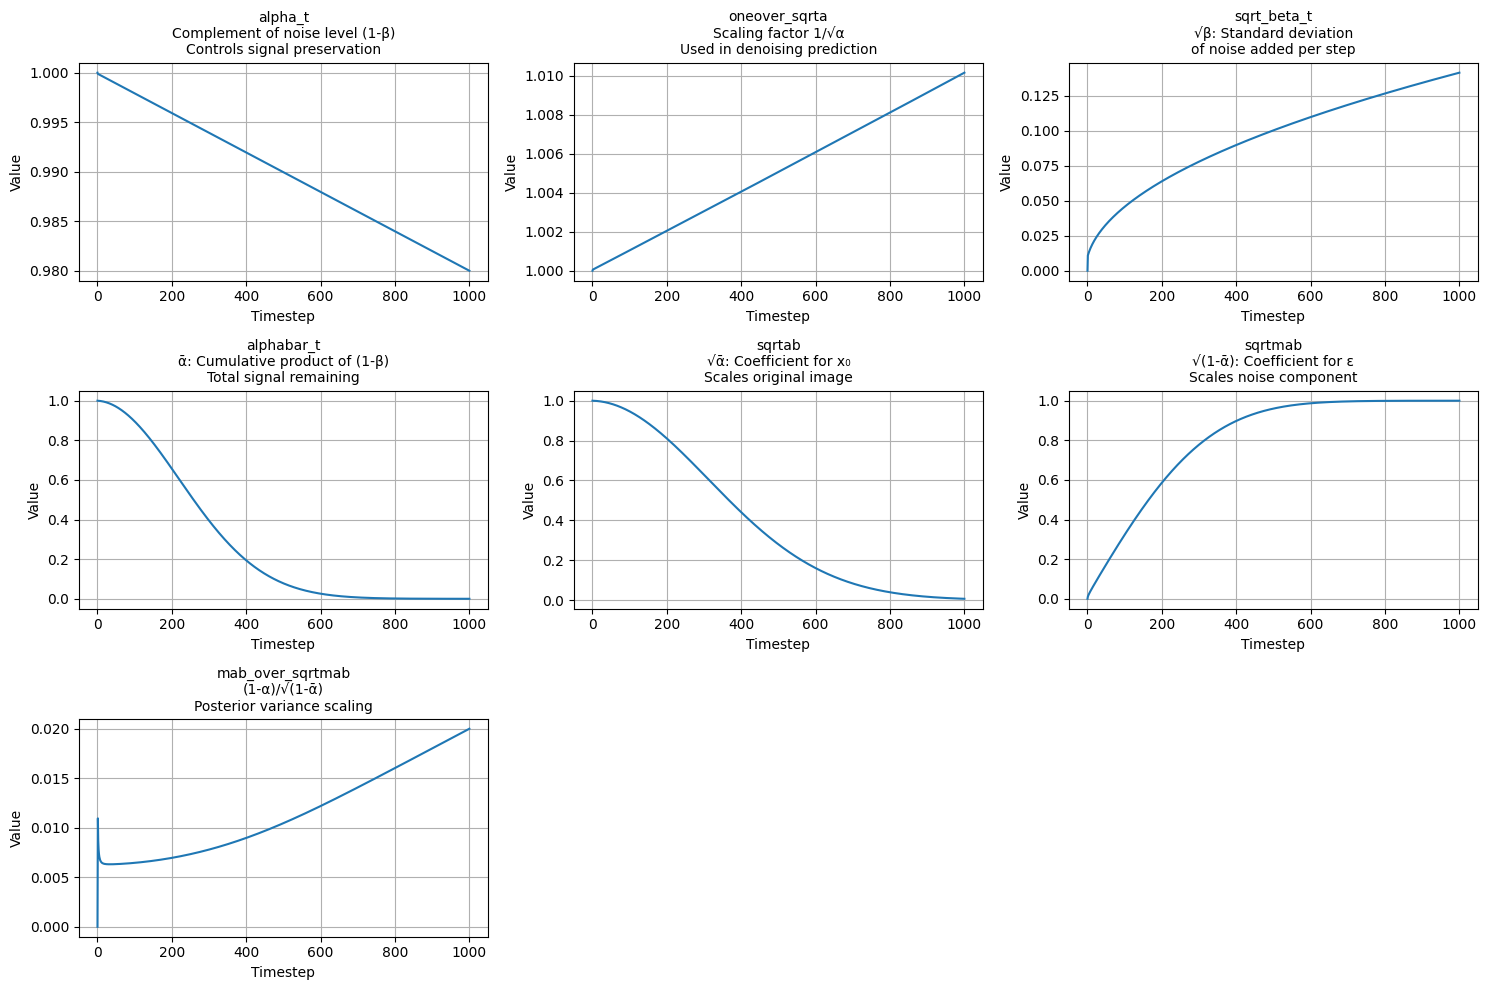

In [ ]:
def plot_ddpm_schedules(beta1: float, beta2: float, T: int):
    """
    Plots the DDPM schedules to visualize how they change over timesteps.
    
    Args:
        beta1: Starting value of noise schedule
        beta2: Ending value of noise schedule  
        T: Number of timesteps
    """
    schedules = ddpm_schedules(beta1, beta2, T)
    
    explanations = {
        "alpha_t": "Complement of noise level (1-β)\nControls signal preservation",
        "oneover_sqrta": "Scaling factor 1/√α\nUsed in denoising prediction",
        "sqrt_beta_t": "√β: Standard deviation\nof noise added per step",
        "alphabar_t": "ᾱ: Cumulative product of (1-β)\nTotal signal remaining",
        "sqrtab": "√ᾱ: Coefficient for x₀\nScales original image",
        "sqrtmab": "√(1-ᾱ): Coefficient for ε\nScales noise component",
        "mab_over_sqrtmab": "(1-α)/√(1-ᾱ)\nPosterior variance scaling"
    }
    
    plt.figure(figsize=(15, 10))
    
    # Plot each schedule on separate subplots
    for idx, (name, values) in enumerate(schedules.items(), 1):
        plt.subplot(3, 3, idx)
        plt.plot(values.numpy())
        plt.title(f"{name}\n{explanations[name]}", fontsize=10)
        plt.xlabel('Timestep')
        plt.ylabel('Value')
        plt.grid(True)
    
    plt.tight_layout()
    plt.show()

plot_ddpm_schedules(0.0001, 0.02, 1000)

### Part 2.2b: Noise predictor model

In [ ]:
from torchvision.utils import save_image, make_grid
import torch.nn as nn

block = lambda ic, oc: nn.Sequential(
    nn.Conv2d(ic, oc, 7, padding=3),
    nn.BatchNorm2d(oc),
    nn.LeakyReLU(),
)

class SimpleEpsModel(nn.Module):
    """
    Basically, any universal R^n -> R^n model should work for denoising, so try some very simple CNN.
    """

    def __init__(self, n_channel: int) -> None:
        super(SimpleEpsModel, self).__init__()
        self.net = nn.Sequential(
            block(n_channel, 64),
            block(64, 128),
            block(128, 256),
            block(256, 128),
            block(128, 64),
            nn.Conv2d(64, n_channel, 7, padding=3),
        )

    def forward(self, x, t) -> torch.Tensor:
        # t is intentionally ignored in this simple version
        return self.net(x)
    
eps_model = SimpleEpsModel(4)
print("Num params: ", sum(p.numel() for p in eps_model.parameters()))

Num params:  4041092


In [ ]:
import torch
import torch.nn as nn
import math

class Block(nn.Module):
    """
    A basic building block for the U-Net architecture that processes both spatial and temporal information.
    
    Args:
        in_ch (int): Number of input channels
        out_ch (int): Number of output channels 
        time_emb_dim (int): Dimension of time embedding
        up (bool): If True, uses transposed convolution for upsampling. If False, uses regular convolution for downsampling
    """
    def __init__(self, in_ch, out_ch, time_emb_dim, up=False):
        super().__init__()
        self.up = up

        if up:
            # Upsampling
            self.conv1     = nn.Conv2d(2 * in_ch, out_ch, 3, padding=1)
            self.transform = nn.ConvTranspose2d(out_ch, out_ch, 4, stride=2, padding=1)
        else:
            # Downsampling
            self.conv1     = nn.Conv2d(in_ch, out_ch, 3, padding=1)
            self.transform = nn.Conv2d(out_ch, out_ch, 4, stride=2, padding=1)

        self.conv2    = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.norm1    = nn.GroupNorm(8, out_ch)
        self.norm2    = nn.GroupNorm(8, out_ch)
        self.act      = nn.SiLU()

        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_emb_dim, out_ch),
        )

    def forward(self, x, t):
        """
        Forward pass of the block.
        
        Args:
            x (torch.Tensor): Input feature maps
            t (torch.Tensor): Time embeddings
            
        Returns:
            torch.Tensor: Transformed feature maps
        """
        h = self.act(self.norm1(self.conv1(x)))

        time_emb = self.time_mlp(t)
        time_emb = time_emb[:, :, None, None]
        h = h + time_emb

        # Second Conv + Norm + Activation
        h = self.act(self.norm2(self.conv2(h)))

        # Final transformation (up/downsampling)
        return self.transform(h)

class SinusoidalPositionEmbeddings(nn.Module):
    """
    Creates sinusoidal positional embeddings for time steps.
    Uses alternating sine and cosine functions at different frequencies.
    
    Args:
        dim (int): Dimension of the embeddings
    """
    
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    

    def forward(self, time):
        """
        Compute positional embeddings for given timesteps.
        
        Args:
            time (torch.Tensor): Tensor of timesteps
            
        Returns:
            torch.Tensor: Position embeddings of shape (batch_size, dim)
        """
        device   = time.device
        half_dim = self.dim // 2
        freqs = torch.exp(
            -math.log(10000) * torch.arange(half_dim, device=device) / half_dim
        )
        # outer product -> (B, half_dim)
        args = time[:, None].float() * freqs[None, :]
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)  # (B, dim)

class SimpleUnet(nn.Module):
    """
    A simplified variant of the Unet architecture for diffusion models.
    Includes time conditioning and skip connections.
    
    Args:
        in_channels (int): Number of input image channels
    """
    def __init__(self, in_channels=4):
        super().__init__()
        image_channels = in_channels
        down_channels = (128, 256, 384)  # Limited the downsampling stages
        up_channels = (384, 256, 128)
        out_dim = in_channels
        time_emb_dim = 256

        # Time embedding layers
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.ReLU()
        )
        

        self.conv0 = nn.Conv2d(image_channels, down_channels[0], 3, padding=1)

        self.downs = nn.ModuleList([
            Block(down_channels[i], down_channels[i + 1], time_emb_dim)
            for i in range(len(down_channels) - 1)
        ])

        self.bottleneck = nn.Sequential(
            nn.Conv2d(down_channels[-1], down_channels[-1], 3, padding=1),
            nn.GroupNorm(8, down_channels[-1]),
            nn.SiLU(),
            nn.Conv2d(down_channels[-1], up_channels[0], 3, padding=1),
            nn.GroupNorm(8, up_channels[0]),
            nn.SiLU(),
        )

        self.ups = nn.ModuleList([
            Block(up_channels[i], up_channels[i + 1], time_emb_dim, up=True)
            for i in range(len(up_channels) - 1)
        ])

        self.output = nn.Sequential(
            nn.Conv2d(up_channels[-1], up_channels[-1], 3, padding=1),
            nn.GroupNorm(8, up_channels[-1]),
            nn.SiLU(),
            nn.Conv2d(up_channels[-1], out_dim, 1),
        )

    def forward(self, x, timestep):
        """
        Forward pass of the U-Net.
        
        Args:
            x (torch.Tensor): Input tensor of shape (batch_size, channels, height, width)
            timestep (torch.Tensor): Current timestep for conditioning
            
        Returns:
            torch.Tensor: Output tensor of same shape as input
        """
        t = self.time_mlp(timestep)

        x = self.conv0(x)

        residual_inputs = []

        # Downsampling path
        for down in self.downs:
            x = down(x, t)
            residual_inputs.append(x)

        x = self.bottleneck(x)

        # Upsampling path with skip connections
        for up in self.ups:
            residual = residual_inputs.pop()
            if x.shape[2:] != residual.shape[2:]:
                x = nn.functional.interpolate(x, size=residual.shape[2:])
            x = torch.cat((x, residual), dim=1)
            x = up(x, t)

        return self.output(x)

# Test the model, your latent input shape will only be [4,14,14], which means that kernel sizes can quickly get larger than input sizes
input_tensor = torch.randn(1, 4, 14, 14)
timestep = torch.tensor([1.0])
UNetModel = SimpleUnet()
output = UNetModel(input_tensor, timestep)
print("Output shape:", output.shape)
print("Num params: ", sum(p.numel() for p in UNetModel.parameters()))

Output shape: torch.Size([1, 4, 14, 14])
Num params:  14057476


### Part 2.2c: Definition of the DDPM

In [ ]:
import torch
import torch.distributions as dist

class DDPM(nn.Module):
    """
    Denoising Diffusion Probabilistic Model (DDPM) implementation.
    
    This class implements the DDPM as described in "Denoising Diffusion Probabilistic Models" 
    (Ho et al., 2020). The model learns to reverse a gradual noising process.
    
    Args:
        eps_model (nn.Module): The neural network that predicts noise at each timestep
        betas (Tuple[float, float]): Beta schedule parameters (β_start, β_end)
        n_T (int): Number of timesteps in the diffusion process
        criterion (nn.Module): Loss function for training, defaults to MSELoss
    """
    def __init__(
        self,
        eps_model: nn.Module,
        betas: Tuple[float, float],
        n_T: int,
        criterion: nn.Module = nn.MSELoss()
    ) -> None:
        super(DDPM, self).__init__()
        self.eps_model = eps_model

        # register_buffer allows us to freely access these tensors by name. It helps device placement.
        for k, v in ddpm_schedules(betas[0], betas[1], n_T).items():
            self.register_buffer(k, v)

        self.n_T = n_T
        self.criterion = criterion

        # Initialize with dataset statistics for potentially better starting point
        mean =  0.04640255868434906
        std_dev = 0.8382343649864197
        self.normal_dist = dist.Normal(mean, std_dev)
        

    def forward(self, x: torch.Tensor, t: torch.Tensor = None) -> torch.Tensor:
        """
        Performs forward diffusion and predicts the noise added at timestep t.
        
        This implements Algorithm 1 from the DDPM paper:
        1. Sample a random timestep t
        2. Sample random noise ε
        3. Create noised input x_t using the noise schedule
        4. Predict the noise using the model
        5. Return the loss between predicted and actual noise
        
        Args:
            x (torch.Tensor): Input images/data
            t (torch.Tensor, optional): Specific timestep. If None, randomly sampled.
            
        Returns:
            Tuple containing:
            - Loss between predicted and actual noise
            - The sampled noise (eps)
            - The noised input at timestep t (x_t)
        """
        _ts = torch.randint(1, self.n_T + 1, (x.shape[0],)).to(x.device)

        eps = torch.randn_like(x)

        x_t = (
            self.sqrtab[_ts, None, None, None] * x
            + self.sqrtmab[_ts, None, None, None] * eps
        )

        # Normalise timestep to [0, 1] for the model
        t_norm   = _ts.float() / self.n_T
        eps_pred = self.eps_model(x_t, t_norm)

        return self.criterion(eps_pred, eps), eps, x_t
    
    def sample(self, n_sample: int, size, device, t = 0) -> torch.Tensor:
        """
        Samples new images using the trained diffusion model.
        
        Implements Algorithm 2 from the DDPM paper - the reverse diffusion process.
        Starting from pure noise, gradually denoise to generate new samples.
        
        Args:
            n_sample (int): Number of samples to generate
            size (tuple): Size of each sample
            device: Device to generate samples on
            t (int): Starting timestep (default=0)
            
        Returns:
            torch.Tensor: Generated samples
        """
        # Start from pure noise
        x_i = torch.randn(n_sample, *size).to(device)  # x_T ~ N(0, 1)
        
        for i in range(self.n_T, t, -1):
            z = torch.randn_like(x_i) if i > 1 else torch.zeros_like(x_i)

            t_norm = torch.tensor([i / self.n_T], device=device).repeat(n_sample)

            eps_pred = self.eps_model(x_i, t_norm)

            x_i = (
                self.oneover_sqrta[i] * (x_i - self.mab_over_sqrtmab[i] * eps_pred)
                + self.sqrt_beta_t[i] * z
            )
        return x_i

### Part 2.2d: Forward diffusion visualisation

Setting up DDPM model with 1000 timesteps...
Original image shape: torch.Size([32, 3, 112, 112])
Encoded latent shape: torch.Size([32, 4, 14, 14])


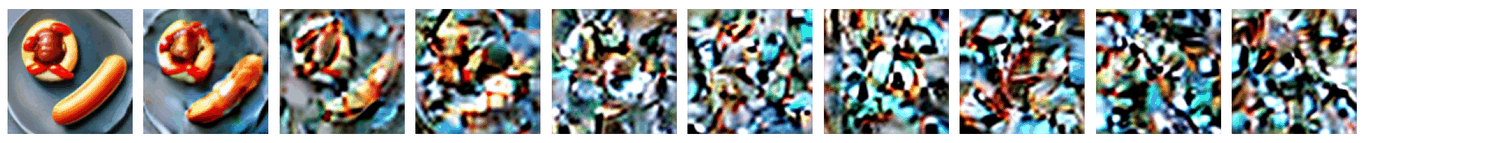

In [ ]:
import torch.distributions as dist

# Helper function to display tensor images
def show_tensor_image(image):
    reverse_transforms = transforms.Compose([
        transforms.ToPILImage(),
    ])
    # Take first image of batch
    if len(image.shape) == 4:
        image = image[0, :, :, :] 
    plt.imshow(reverse_transforms(image))

# Set up DDPM model parameters
print("Setting up DDPM model with 1000 timesteps...")
T = 1000

ddpm = DDPM(
    eps_model=SimpleUnet(in_channels=4),
    betas=(1e-4, 0.02),
    n_T=T,
).to(device)

image = next(iter(hotdogdata_loader_test_112))[0]
print(f"Original image shape: {image.shape}")
image = image.to(device)

emb = sd_vae.encode(image)
latent_shape = emb.shape
print(f"Encoded latent shape: {emb.shape}")

plt.figure(figsize=(20, 2))
plt.axis('off')
num_images = 10
stepsize = int(T / num_images)

for idx in range(0, T, stepsize):
    t_val= torch.tensor([idx + 1]).to(device)
    eps = torch.randn_like(emb)
    noisy_emb = (
        ddpm.sqrtab[t_val, None, None, None] * emb
        + ddpm.sqrtmab[t_val, None, None, None] * eps
    )
    img = sd_vae.decode(noisy_emb)
    plt.subplot(1, num_images + 1, int(idx / stepsize) + 1)
    plt.axis('off')
    show_tensor_image(img.cpu())

plt.tight_layout()

### Hot dog classifier

In [ ]:
from icl_dl_cw2_utils.utils.food_resnet import HotDogClassifier
hotdogclassifier = HotDogClassifier(checkpoint_path=content_path/'hotdogdetect_checkpoint.pth')

## Part 2.3: Training the latent diffusion model

In [ ]:
sample_img  = next(iter(hotdogdata_loader_train_112))[0][:1].to(device)
with torch.no_grad():
    emb_sample = sd_vae.encode(sample_img)

img_shape = tuple(sample_img.shape)  
emb_shape= tuple(emb_sample.shape) 
latent_shape = emb_sample.shape  

print("Input image shape (batch_size, channels, height, width):", img_shape)
print("VAE encoded latent shape:", emb_shape)
print("Final latent shape for model input:", latent_shape)

del sample_img, emb_sample 

rn_rn_model = None
model_choice = 1 

if model_choice == 0:
    eps_model = SimpleEpsModel(emb_shape[1])
    rn_rn_model = eps_model.to(device)
    print("SimpleEpsModel total trainable parameters:",
          sum(p.numel() for p in eps_model.parameters()))
    model_path = content_path / 'CW_LDM/ldm_hotdogs_dummyeps.pth'

elif model_choice == 1:
    simple_unet = SimpleUnet(in_channels=emb_shape[1])
    rn_rn_model= simple_unet.to(device)
    print("SimpleUnet total trainable parameters:",
          sum(p.numel() for p in simple_unet.parameters()))
    model_path = content_path / 'CW_LDM/ldm_hotdogs_simple_unet_cls.pth'

# Hyperparameters
T_steps = 1000
beta1 = 1e-4
beta2= 0.02
lr = 1e-4

ddpm = DDPM(
    eps_model=rn_rn_model,
    betas=(beta1, beta2),
    n_T=T_steps,
).to(device)

optim = torch.optim.Adam(ddpm.parameters(), lr=lr)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optim, T_max=400, eta_min=1e-6
)

ema_model = SimpleUnet(in_channels=emb_shape[1]).to(device)
ema_model.load_state_dict(rn_rn_model.state_dict())

def update_ema(ema_model, model, decay=0.995):
    with torch.no_grad():
        for ema_p, p in zip(ema_model.parameters(), model.parameters()):
            ema_p.data.mul_(decay).add_(p.data, alpha=1 - decay)

# ===== 4. Checkpoint Loading (Optional) =====
lastepoch = 0
load_checkpoint = True
if os.path.exists(model_path) and load_checkpoint:
    print("Loading existing model checkpoint from:", model_path)
    checkpoint = torch.load(model_path)
    ddpm.load_state_dict(checkpoint['model_state_dict'])
    optim.load_state_dict(checkpoint['optimizer_state_dict'])
    lastepoch = checkpoint['epoch'] + 1  # continue from the next epoch
    # Restore EMA if saved, otherwise copy from loaded model
    if 'ema_state_dict' in checkpoint:
        ema_model.load_state_dict(checkpoint['ema_state_dict'])
    else:
        ema_model.load_state_dict(ddpm.eps_model.state_dict())
    # Restore scheduler if saved, otherwise fast-forward manually
    if 'scheduler_state_dict' in checkpoint:
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    else:
        for _ in range(lastepoch):
            scheduler.step()
    print(f"Resumed from epoch {lastepoch}")

ddpm.to(device)

# ===== 5. Training Loop =====
# Initialize tracking variables
example = None
input_sample = None
best_hd_prob = 0
best_hd_image = None

# Initialize widgets
import ipywidgets as widgets
from IPython.display import display, clear_output

n_epoch = 635 # Train for at least a few hundred epochs (several hours)

# Progress bar to track training progress across epochs
progress_bar = widgets.FloatProgress(
    value=0,
    min=0,
    max=n_epoch,
    description=f'Training (0/{n_epoch} epochs):',
    style={'description_width': 'initial'}
)
loss_text = widgets.HTML(value='Current loss: -')
image_output = widgets.Output()
display(widgets.VBox([progress_bar, loss_text, image_output]))

# Main training loop
for i in range(lastepoch, n_epoch):
    # Training phase
    ddpm.train()
    batch_pbar = tqdm(hotdogdata_loader_train_112, leave=False)
    loss_ema = None
    loss_comb_ema = None
    
    # Process each batch
    for x, _ in batch_pbar:
        optim.zero_grad()
        x = x.to(device)
        with torch.no_grad():
            z = sd_vae.encode(x)  

        # Forward pass: compute denoising loss
        loss, _, _ = ddpm(z)

        loss_ema = loss.item() if loss_ema is None else 0.9 * loss_ema + 0.1 * loss.item()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(ddpm.parameters(), 1.0)
        batch_pbar.set_description(f"Training loss (EMA): {loss_ema:.4f}")
        optim.step()
        update_ema(ema_model, rn_rn_model)
    
    scheduler.step()
    # Update progress widgets
    progress_bar.value = i
    progress_bar.description = f'Training ({i+1}/{n_epoch} epochs):'
    loss_text.value = f'Current loss: {loss_ema:.4f}'

    # ===== 6. Evaluation and Sample Generation =====
    ddpm.eval()
    with torch.no_grad():
        ddpm.eps_model.load_state_dict(ema_model.state_dict())
        xh = ddpm.sample(16, (latent_shape[1], latent_shape[2], latent_shape[3]), device)
        ddpm.eps_model.load_state_dict(rn_rn_model.state_dict())
        xh = sd_vae.decode(xh)
        
        # Save generated and input samples
        grid = make_grid(xh, nrow=4)
        save_image(grid, content_path/f'CW_LDM/ldm_sample_{i}.png')
        grid1 = make_grid(x, nrow=4)
        save_image(grid1, content_path/f'CW_LDM/input_sample_{i}.png')
        
        # Evaluate with hotdog classifier
        predictions, probabilities, top5_accuracy = hotdogclassifier.predict(xh.detach())
        
        # Track best results
        example = xh
        input_sample = x
        column_55_values = probabilities[:, 55]
        best_hd_prob_idx = torch.argmax(column_55_values)
        best_hd_prob_current = torch.max(column_55_values)
        
        # Update and display best hotdog image
        if best_hd_prob_current > best_hd_prob:
            best_hd_prob = best_hd_prob_current
            best_hd_image = xh[best_hd_prob_idx,:,:,:]
            
            with image_output:
                clear_output(wait=True)
                plt.figure(figsize=(8, 8))
                imshow(best_hd_image, plt.gca())
                plt.title(f'Best generated hot dog (confidence: {best_hd_prob:.3f})')
                plt.savefig(content_path/f'CW_LDM/best_hot_dog_{i}.png')
                plt.close()
        
        # Save checkpoint (model, optimiser, scheduler and EMA state)
        state = {
            'epoch': i,
            'model_state_dict': ddpm.state_dict(),
            'optimizer_state_dict': optim.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'ema_state_dict': ema_model.state_dict(),
            'loss': loss_ema,
        }
        torch.save(state, model_path)

Input image shape (batch_size, channels, height, width): (1, 3, 112, 112)
VAE encoded latent shape: (1, 4, 14, 14)
Final latent shape for model input: torch.Size([1, 4, 14, 14])
SimpleUnet total trainable parameters: 14057476
Loading existing model checkpoint from: dl/dl_cw2/CW_LDM/ldm_hotdogs_simple_unet_cls.pth
Resumed from epoch 630


### Sample visualisation

In [ ]:
with torch.no_grad():
    predictions, probabilities, top5_accuracy = hotdogclassifier.predict(example)

    hotdog_scores = probabilities[:, 55]
    sorted_idx = torch.argsort(hotdog_scores, descending=True)

    # Show the top 6 generated samples
    fig, axes = plt.subplots(2, 3, figsize=(6, 4))
    for rank, idx in enumerate(sorted_idx[:6]):
        img = example[idx].cpu().permute(1, 2, 0).clamp(0, 1).numpy()
        ax = axes[rank // 3][rank % 3]
        ax.imshow(img)
        score = hotdog_scores[idx].item()
        ax.set_title(f'Hotdog: {score:.1%}', fontsize=14)
        ax.axis('off')

    plt.suptitle('Top 6 Generated Hotdogs\n', fontsize=12, y=1.15)
    plt.tight_layout()
    plt.subplots_adjust(top=1)
    plt.savefig(content_path / 'CW_LDM/top6_generated_hotdogs.png')
    plt.show()

Generating images...
--------------------------------------------------


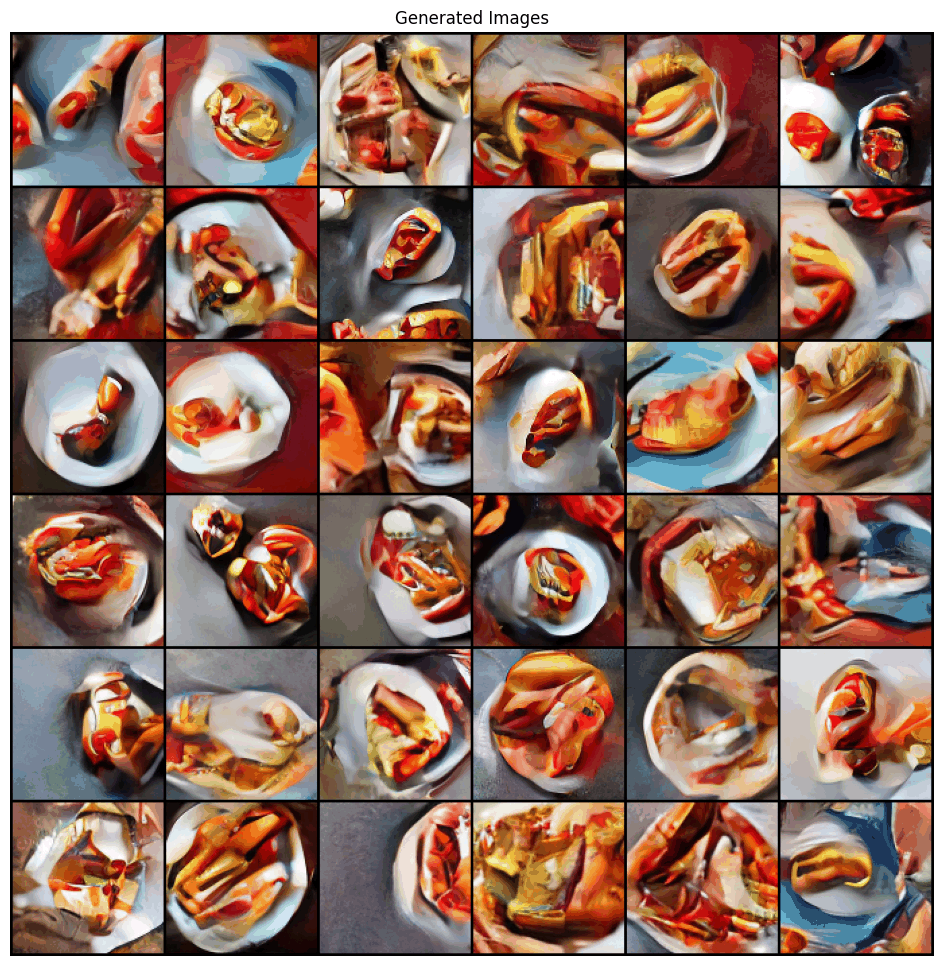

In [ ]:
# Generate a grid of images using the DDPM model
print('Generating images...')
print('-'*50)
ddpm.eval() 
with torch.no_grad():
    n_samples = 36
    
    x_latent = ddpm.sample(n_samples, 
                          (latent_shape[1], latent_shape[2], latent_shape[3]), 
                          device)
    
    # decode latent samples to image space using the VAE decoder
    x_generated = sd_vae.decode(x_latent)
    
    x_generated = x_generated.cpu()
    grid = make_grid(x_generated, nrow=6, padding=2, normalize=True,
                    value_range=(0, 1), scale_each=False, pad_value=0)
    
    plt.figure(figsize=(12, 12))
    show(grid)
    plt.title('Generated Images')
    plt.savefig(content_path / f'CW_LDM/final_hotdogs_new.png')
    plt.show()